# 01. Fundamentos Probabilísticos y el Teorema de Bayes en Clasificación

**Módulo:** `05_Naive_Bayes`  
**Objetivo:** Comprender a nivel algebraico, geométrico, epistemológico y computacional el paradigma generativo de clasificación, la cronología de actualización de creencias del Teorema de Bayes (evitando la falacia de la tasa base), la diferencia crítica entre independencia marginal y condicional, la deducción rigurosa de la regla *Maximum A Posteriori* (MAP) y su implementación desde cero en espacio logarítmico.

---

## 1. Paradigma Generativo vs. Discriminativo

### Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
Imagina que lideras el equipo de Machine Learning en una *Fintech* o en un hospital oncológico y debes elegir la arquitectura para un nuevo clasificador de riesgo:
* **Escenario A:** Acabas de lanzar un producto financiero nuevo y apenas tienes **$N = 150$ transacciones etiquetadas**, o bien algunos sensores fallan en producción dejando **valores nulos (`NaN`)** en tiempo real, o necesitas detectar si una transacción entrante es una **anomalía total** jamás vista en el entrenamiento.
* **Escenario B:** Tienes **5 millones de registros históricos limpios**, cientos de variables correlacionadas y tu único objetivo es trazar la frontera de separación más fina posible para maximizar el *ROC-AUC*.

**¿Por qué una empresa elegiría un modelo Generativo (como Naive Bayes) en el Escenario A, y uno Discriminativo (como Regresión Logística) en el Escenario B?**  
Porque un modelo **discriminativo** funciona como un *juez de aduanas* que solo memoriza la línea divisoria entre clases, mientras que un modelo **generativo** funciona como un *falsificador experto*: estudia e interioriza la receta completa de cómo se fabrica cada clase desde adentro.

---

### Paso 2: Formalismo Matemático Riguroso

En el aprendizaje supervisado para clasificación, dado un espacio de características $\mathcal{X} \subseteq \mathbb{R}^D$ (donde cada instancia es un vector $\mathbf{x} = (x_1, x_2, \dots, x_D)^\top$) y un espacio de etiquetas discretas $\mathcal{Y} = \{c_1, c_2, \dots, c_C\}$, el objetivo fundamental es aprender una función de asignación $f: \mathcal{X} \to \mathcal{Y}$ a través de la distribución condicional $P(Y = c_k \mid \mathbf{X} = \mathbf{x})$.

#### A. Modelos Discriminativos
Parametrizan y optimizan **directamente** la distribución condicional $P(Y \mid \mathbf{X}; \boldsymbol{\theta})$ o aprenden un hiperplano geométrico de separación sin modelar el mecanismo generador de las características $\mathbf{X}$.
* **Ejemplos:** Regresión Logística, Máquinas de Vectores de Soporte (SVM), Árboles de Decisión (CART), Redes Neuronales.
* **Enfoque:** Maximizar la verosimilitud condicional $\prod_{i=1}^N P(y^{(i)} \mid \mathbf{x}^{(i)})$ (equivalente a minimizar la pérdida de entropía cruzada *Log-Loss*) o maximizar el margen geométrico.

#### B. Modelos Generativos
Modelan la **distribución de probabilidad conjunta** $P(\mathbf{X}, Y)$ factorizándola en dos componentes: primero aprenden la prevalencia base de cada clase $P(Y)$ y cómo cada clase *genera* sus vectores de características $P(\mathbf{X} \mid Y)$:

$$P(\mathbf{X} = \mathbf{x}, Y = c_k) = P(Y = c_k) \cdot P(\mathbf{X} = \mathbf{x} \mid Y = c_k)$$

Posteriormente, invierten el condicionamiento mediante el **Teorema de Bayes** para deducir la probabilidad predictiva $P(Y = c_k \mid \mathbf{X} = \mathbf{x})$.
* **Ejemplos:** Clasificadores Naive Bayes, Análisis Discriminante Lineal y Cuadrático (LDA / QDA), Modelos Ocultos de Markov (HMM), Modelos de Mezclas Gaussianas (GMM).

---

### Paso 3: Traducción "En Palabras Claras" (El Puente Conceptual y Tabla Comparativa)

| Criterio Técnico y de Negocio | Paradigma Generativo (Naive Bayes, LDA/QDA, HMM) | Paradigma Discriminativo (Regresión Logística, SVM, Redes) |
| :--- | :--- | :--- |
| **¿Qué distribución modela?** | La distribución conjunta $P(\mathbf{x}, y) = P(\mathbf{x} \mid y)P(y)$. Modela explícitamente cómo se distribuyen las *features* $\mathbf{x}$ en cada clase. | Directamente la frontera condicional $P(y \mid \mathbf{x})$. No gasta capacidad paramétrica en modelar cómo se generan las *features* $\mathbf{x}$. |
| **Convergencia y Eficiencia Muestral (Ng & Jordan, 2001)** | **Alta velocidad ($\mathcal{O}(\log D)$):** Alcanza su error asintótico con muy pocas muestras ($N$ pequeño). Ideal para *Cold Start*. | **Menor velocidad inicial ($\mathcal{O}(D)$):** Requiere más datos para no sobreajustar, pero con $N \to \infty$ alcanza menor error asintótico. |
| **Generación de Datos Sintéticos** | **Sí:** Permite muestrear $\mathbf{x}_{\text{nuevo}} \sim P(\mathbf{X} \mid Y = c_k)$ para simular escenarios. | **No:** Solo puede evaluar etiquetas dado un vector $\mathbf{x}$ ya existente. |
| **Detección de Anomalías / *Out-of-Distribution*** | **Nativa:** Si la evidencia marginal $P(\mathbf{x}) = \sum_k P(\mathbf{x} \mid c_k)P(c_k)$ es diminuta, alerta que la muestra es un *outlier* desconocido. | **Ciega:** Puede asignar $P(y=1 \mid \mathbf{x}) = 0.99$ a un punto totalmente alejado de los datos de entrenamiento si cae del lado positivo del hiperplano. |
| **Tolerancia a Valores Nulos (`NaN`) en Inferencia** | **Natural:** Si falta la característica $x_j$, simplemente se marginaliza (se omite ese factor del producto) sin requerir imputación artificial. | **Requiere Imputación Previa:** El producto punto $\mathbf{w}^\top \mathbf{x}$ falla si existe un solo `NaN`. |
| **Sensibilidad a Variables Colineales** | **Alta en probabilidades:** Cuenta doble la información repetida, empujando las probabilidades hacia $0$ o $1$. | **Baja:** Ajusta los pesos $w_j$ conjuntamente (especialmente con regularización L1/L2) para compensar colinealidades. |

In [2]:
# Configuración del entorno y librerías estándar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import accuracy_score, brier_score_loss

# Estándar visual del repositorio
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)

print("Entorno configurado correctamente.")

Entorno configurado correctamente.


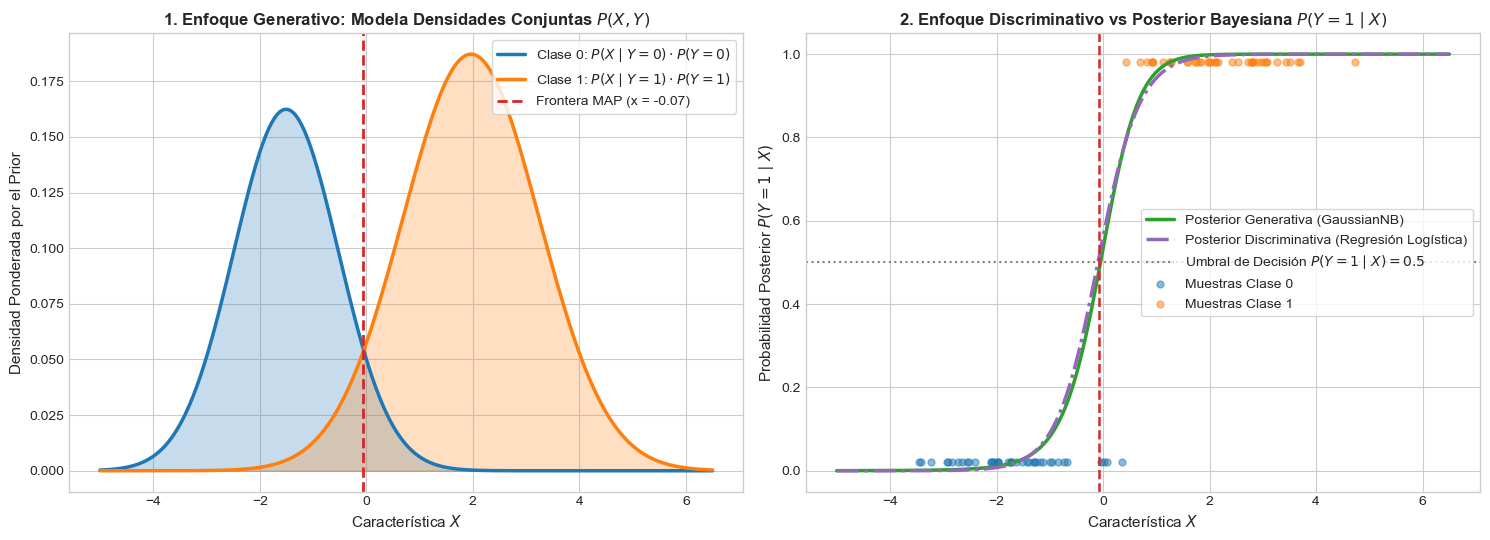

 Interpretación de Negocio:
• En el Panel 1, GaussianNB reconstruye la anatomía completa de ambas clases y ubica el corte exacto en x = -0.07, donde las densidades ponderadas se cruzan.
• Si llegara una observación anómala en x = -15.0, Regresión Logística solo ve que está a la izquierda y asigna 100% de certeza a Clase 0; GaussianNB, en cambio, detecta que tanto pdf_0 como pdf_1 son ~0.0 (alerta de anomalía).


In [7]:
# Paso 4: Código, Visualización e Interpretación de Negocio (Generativo vs Discriminativo en 1D)
np.random.seed(42)

# Generación de datos sintéticos para dos clases
x_c0 = np.random.normal(loc=-1.5, scale=1.0, size=300)
x_c1 = np.random.normal(loc=2.0, scale=1.3, size=450) # Clase 1 más frecuente (Prior mayor)

X_1d = np.concatenate([x_c0, x_c1]).reshape(-1, 1)
y_1d = np.array([0]*300 + [1]*450)

# Ajuste de modelos
gnb_1d = GaussianNB().fit(X_1d, y_1d)
lr_1d = LogisticRegression().fit(X_1d, y_1d)

x_grid = np.linspace(-5, 6.5, 500).reshape(-1, 1)

# Densidades generativas P(X|Y) * P(Y)
prior_0, prior_1 = gnb_1d.class_prior_
pdf_0 = stats.norm.pdf(x_grid.ravel(), loc=gnb_1d.theta_[0, 0], scale=np.sqrt(gnb_1d.var_[0, 0])) * prior_0
pdf_1 = stats.norm.pdf(x_grid.ravel(), loc=gnb_1d.theta_[1, 0], scale=np.sqrt(gnb_1d.var_[1, 0])) * prior_1

# Probabilidades posteriores P(Y=1|X)
post_gnb = gnb_1d.predict_proba(x_grid)[:, 1]
post_lr = lr_1d.predict_proba(x_grid)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel 1: Perspectiva Generativa
axes[0].plot(x_grid, pdf_0, label=r'Clase 0: $P(X \mid Y=0) \cdot P(Y=0)$', color='#1f77b4', lw=2.5)
axes[0].fill_between(x_grid.ravel(), pdf_0, color='#1f77b4', alpha=0.25)
axes[0].plot(x_grid, pdf_1, label=r'Clase 1: $P(X \mid Y=1) \cdot P(Y=1)$', color='#ff7f0e', lw=2.5)
axes[0].fill_between(x_grid.ravel(), pdf_1, color='#ff7f0e', alpha=0.25)

# Encontrar punto de intersección (frontera bayesiana)
idx_intersect = np.argwhere(np.diff(np.sign(pdf_0 - pdf_1))).flatten()[0]
x_frontera = x_grid.ravel()[idx_intersect]
axes[0].axvline(x_frontera, color='#d62728', linestyle='--', lw=2, label=f'Frontera MAP (x = {x_frontera:.2f})')
axes[0].set_title('1. Enfoque Generativo: Modela Densidades Conjuntas $P(X, Y)$', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Característica $X$', fontsize=11)
axes[0].set_ylabel('Densidad Ponderada por el Prior', fontsize=11)
axes[0].legend(frameon=True, facecolor='white')

# Panel 2: Perspectiva Discriminativa / Posterior
axes[1].plot(x_grid, post_gnb, label='Posterior Generativa (GaussianNB)', color='#2ca02c', lw=2.5)
axes[1].plot(x_grid, post_lr, label='Posterior Discriminativa (Regresión Logística)', color='#9467bd', lw=2.5, linestyle='-.')
axes[1].axhline(0.5, color='gray', linestyle=':', lw=1.5, label='Umbral de Decisión $P(Y=1 \mid X) = 0.5$')
axes[1].axvline(x_frontera, color='#d62728', linestyle='--', lw=1.8)
axes[1].scatter(x_c0[:40], np.zeros(40) + 0.02, color='#1f77b4', alpha=0.5, s=25, label='Muestras Clase 0')
axes[1].scatter(x_c1[:40], np.ones(40) - 0.02, color='#ff7f0e', alpha=0.5, s=25, label='Muestras Clase 1')
axes[1].set_title('2. Enfoque Discriminativo vs Posterior Bayesiana $P(Y=1 \mid X)$', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Característica $X$', fontsize=11)
axes[1].set_ylabel('Probabilidad Posterior $P(Y=1 \mid X)$', fontsize=11)
axes[1].legend(frameon=True, facecolor='white', loc='center right')

plt.tight_layout()
plt.show()

print(" Interpretación de Negocio:")
print(f"• En el Panel 1, GaussianNB reconstruye la anatomía completa de ambas clases y ubica el corte exacto en x = {x_frontera:.2f}, donde las densidades ponderadas se cruzan.")
print("• Si llegara una observación anómala en x = -15.0, Regresión Logística solo ve que está a la izquierda y asigna 100% de certeza a Clase 0; GaussianNB, en cambio, detecta que tanto pdf_0 como pdf_1 son ~0.0 (alerta de anomalía).")

Un modelo generativo se pregunta: «¿Cómo es la anatomía completa de cada clase y qué tan probable es que cada una genere este dato?»

Un modelo discriminativo se pregunta únicamente: «No me importa cómo se generaron los datos; ¿dónde pongo la línea de corte para separarlos y cuál es la probabilidad de pertenecer a la Clase 1?»   Ambos paneles muestran el mismo problema con dos clases sintéticas:Clase 0: 300 muestras con media $\mu = -1.5$.   Clase 1: 450 muestras con media $\mu = 2.0$ (es más frecuente, representa el $60\%$ de los datos).   

Panel 1: Perspectiva Generativa (Modelar $P(X, Y)$)Este panel muestra cómo "entiende el mundo" GaussianNB:Eje horizontal ($X$): El valor numérico de la característica medida.Eje vertical: Densidad de probabilidad conjunta $P(X, Y = c_k) = P(X \mid Y = c_k) \cdot P(Y = c_k)$. Representa qué tan probable es encontrar una observación con ese valor específico de $X$ perteneciente a esa clase.La campana azul (Clase 0): Modela la distribución de la Clase 0. Está centrada en $-1.5$.La campana naranja (Clase 1): Modela la distribución de la Clase 1. Está centrada en $2.0$ y es visiblemente más alta porque tiene mayor prevalencia base (prior de $0.60$ vs $0.40$).La línea roja discontinua ($x \approx -0.07$): Es la frontera de decisión MAP (Maximum A Posteriori). Es el punto exacto donde ambas curvas se cruzan:
$$P(X \mid Y=0) \cdot P(Y=0) = P(X \mid Y=1) \cdot P(Y=1)$$A la izquierda de $-0.07$, la campana azul es más alta: el modelo predice Clase 0.   A la derecha de $-0.07$, la campana naranja es más alta: el modelo predice Clase 1.   

Panel 2: Perspectiva Discriminativa y Probabilidades PosterioresEste panel traduce la decisión a una probabilidad de salida directa $P(Y=1 \mid X)$, que es lo que devuelven los métodos predict_proba:Eje vertical: La probabilidad calculada de pertenecer a la Clase 1 (de $0.0$ a $1.0$).   Los puntos dispersos (scatter): Son muestras reales del conjunto de datos. Los azules están abajo ($Y=0$) y los naranjas arriba ($Y=1$).   La curva verde (GaussianNB invertido vía Bayes): Es la probabilidad posterior obtenida al normalizar las dos campanas del Panel 1:
   $$P(Y=1 \mid X) = \frac{P(X, Y=1)}{P(X, Y=0) + P(X, Y=1)}$$La curva morada discontinua (Regresión Logística): Modela esta sigmoide directamente mediante optimización numérica de los coeficientes $w$ y $b$ ($P(Y=1 \mid X) = \sigma(wX + b)$), sin calcular jamás las campanas del Panel 1.   El cruce en $0.5$ (línea gris): Observa que ambas curvas (verde y morada) cruzan exactamente el umbral de indecisión ($50\%$) en la misma coordenada $x \approx -0.07$ donde las campanas del Panel 1 se cortaban. Ambos modelos coinciden casi al $100\%$ en sus predicciones porque los datos reales provienen de normales exactas.

¿Por qué importa la diferencia?Aunque ambas curvas en el Panel 2 se ven casi idénticas, se comportan de forma radicalmente distinta en situaciones atípicas:Si entra un dato extremo en $X = -15$:Regresión Logística (Discriminativo): Solo evalúa la sigmoide hacia la izquierda. Concluye con un $100\%$ de certeza que el registro es Clase 0. No tiene noción de si el dato tiene sentido o no; simplemente está "muy a la izquierda de la frontera".GaussianNB (Generativo): Evalúa la campana azul y la naranja en $-15$. Descubre que tanto la densidad de la Clase 0 como la de la Clase 1 son prácticamente $0.000000$. Esto permite levantar una bandera de anomalía u outlier: el modelo sabe que ninguna de las dos clases produce habitualmente valores tan lejanos.Faltantes / Valores Nulos ($NaN$):Si tienes $D$ dimensiones y una de ellas viene vacía, un modelo generativo puede simplemente ignorar esa variable marginalizándola ($P(X_2 \mid Y)$) y seguir clasificando con las restantes.   Un modelo discriminativo tradicional (como regresión logística o redes neuronales) falla porque su producto punto $w^T x$ se vuelve indeterminado sin imputación previa de datos.



--- RESULTADOS EN X = -12.0 (ANOMALÍA) ---
Regresión Logística: P(Y=0|X) = 1.000000 | P(Y=1|X) = 0.000000
GaussianNB (Evidencia total P(X)): 2.98e-26
GaussianNB: Densidad Clase 0 = 2.74e-26 | Densidad Clase 1 = 2.35e-27



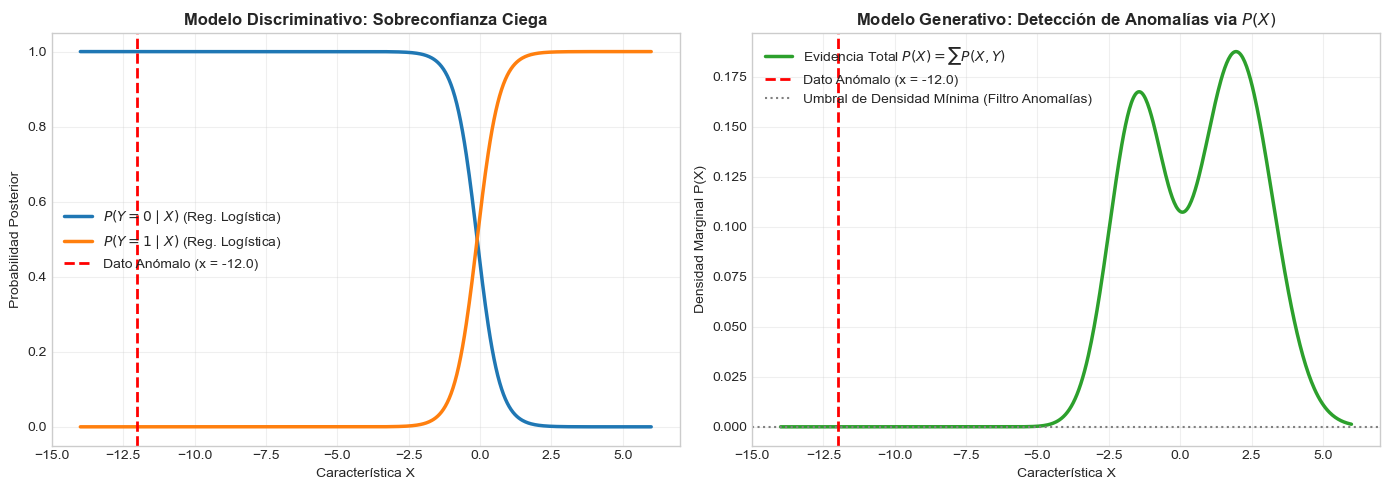

--- COMPORTAMIENTO CON VALORES FALTANTES ---
Error en Regresión Logística: Input X contains NaN.
LogisticRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

GaussianNB marginalizado (usando solo X1 = 1.5):
P(Y=0 | X1=1.5) = 0.0048
P(Y=1 | X1=1.5) = 0.9952



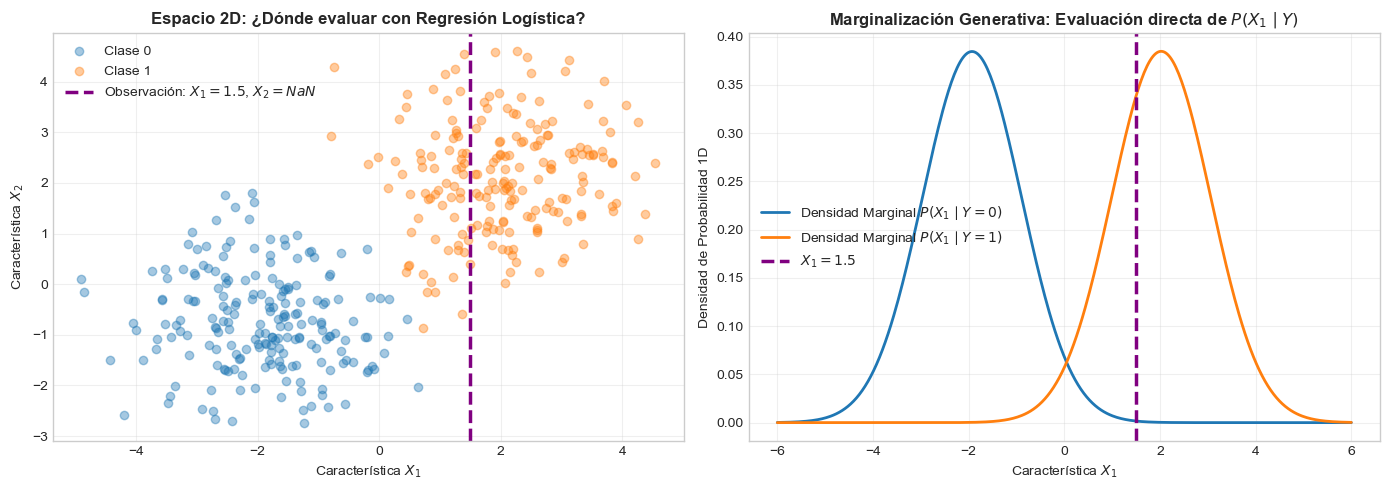

In [9]:

# ==============================================================================
# CASO 1: COMPORTAMIENTO FRENTE A DATOS EXTREMOS (OUTLIERS / ANOMALÍAS)
# ==============================================================================

np.random.seed(42)

# Datos 1D
x_c0 = np.random.normal(loc=-1.5, scale=1.0, size=300)
x_c1 = np.random.normal(loc=2.0, scale=1.3, size=450)
X_1d = np.concatenate([x_c0, x_c1]).reshape(-1, 1)
y_1d = np.array([0] * 300 + [1] * 450)

gnb = GaussianNB().fit(X_1d, y_1d)
lr = LogisticRegression().fit(X_1d, y_1d)

# Simulación de un dato extremo / anómalo
x_anomalo = np.array([[-12.0]])

# 1. Predicciones con Regresión Logística
prob_lr = lr.predict_proba(x_anomalo)[0]

# 2. Predicciones y Densidad con GaussianNB
prior_0, prior_1 = gnb.class_prior_
densidad_c0 = stats.norm.pdf(x_anomalo[0, 0], loc=gnb.theta_[0, 0], scale=np.sqrt(gnb.var_[0, 0])) * prior_0
densidad_c1 = stats.norm.pdf(x_anomalo[0, 0], loc=gnb.theta_[1, 0], scale=np.sqrt(gnb.var_[1, 0])) * prior_1
evidencia_total_px = densidad_c0 + densidad_c1

print("--- RESULTADOS EN X = -12.0 (ANOMALÍA) ---")
print(f"Regresión Logística: P(Y=0|X) = {prob_lr[0]:.6f} | P(Y=1|X) = {prob_lr[1]:.6f}")
print(f"GaussianNB (Evidencia total P(X)): {evidencia_total_px:.2e}")
print(f"GaussianNB: Densidad Clase 0 = {densidad_c0:.2e} | Densidad Clase 1 = {densidad_c1:.2e}\n")

# Gráfica Caso 1
x_grid = np.linspace(-14, 6, 600).reshape(-1, 1)
pdf_c0_grid = stats.norm.pdf(x_grid.ravel(), loc=gnb.theta_[0, 0], scale=np.sqrt(gnb.var_[0, 0])) * prior_0
pdf_c1_grid = stats.norm.pdf(x_grid.ravel(), loc=gnb.theta_[1, 0], scale=np.sqrt(gnb.var_[1, 0])) * prior_1
px_grid = pdf_c0_grid + pdf_c1_grid

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot A: Regresión Logística (confianza ciega)
axes[0].plot(x_grid, lr.predict_proba(x_grid)[:, 0], label=r'$P(Y=0 \mid X)$ (Reg. Logística)', color='#1f77b4', lw=2.5)
axes[0].plot(x_grid, lr.predict_proba(x_grid)[:, 1], label=r'$P(Y=1 \mid X)$ (Reg. Logística)', color='#ff7f0e', lw=2.5)
axes[0].axvline(x_anomalo[0, 0], color='red', linestyle='--', lw=2, label=f'Dato Anómalo (x = {x_anomalo[0,0]})')
axes[0].set_title('Modelo Discriminativo: Sobreconfianza Ciega', fontweight='bold')
axes[0].set_xlabel('Característica X')
axes[0].set_ylabel('Probabilidad Posterior')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Subplot B: GaussianNB (Evidencia total P(X))
axes[1].plot(x_grid, px_grid, label=r'Evidencia Total $P(X) = \sum P(X, Y)$', color='#2ca02c', lw=2.5)
axes[1].axvline(x_anomalo[0, 0], color='red', linestyle='--', lw=2, label=f'Dato Anómalo (x = {x_anomalo[0,0]})')
axes[1].axhline(1e-4, color='gray', linestyle=':', label='Umbral de Densidad Mínima (Filtro Anomalías)')
axes[1].set_title('Modelo Generativo: Detección de Anomalías via $P(X)$', fontweight='bold')
axes[1].set_xlabel('Característica X')
axes[1].set_ylabel('Densidad Marginal P(X)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ==============================================================================
# CASO 2: VALORES FALTANTES (NaN) POR MARGINALIZACIÓN DIRECTA EN 2D
# ==============================================================================

# Generación de datos 2D (2 características correlacionadas o independientes)
X_c0_2d = np.random.multivariate_normal(mean=[-2, -1], cov=[[1.0, 0.0], [0.0, 1.2]], size=200)
X_c1_2d = np.random.multivariate_normal(mean=[2, 2], cov=[[1.2, 0.0], [0.0, 1.0]], size=200)
X_2d = np.vstack([X_c0_2d, X_c1_2d])
y_2d = np.array([0] * 200 + [1] * 200)

gnb_2d = GaussianNB().fit(X_2d, y_2d)
lr_2d = LogisticRegression().fit(X_2d, y_2d)

# Muestra entrante incompleta: conocemos x1 = 1.5, pero x2 es NaN
x_incompleto = np.array([[1.5, np.nan]])

# 1. Regresión Logística falla al operar con NaN
try:
    lr_2d.predict_proba(x_incompleto)
except ValueError as e:
    print("--- COMPORTAMIENTO CON VALORES FALTANTES ---")
    print(f"Error en Regresión Logística: {e}")

# 2. Naive Bayes: Inferencia Exacta por Marginalización
# Como P(X1, X2 | Y) = P(X1 | Y) * P(X2 | Y), integrar sobre X2 da:
# Integral P(X1, X2 | Y) dX2 = P(X1 | Y) * 1 = P(X1 | Y)
x1_val = 1.5
dens_c0_x1 = stats.norm.pdf(x1_val, loc=gnb_2d.theta_[0, 0], scale=np.sqrt(gnb_2d.var_[0, 0])) * gnb_2d.class_prior_[0]
dens_c1_x1 = stats.norm.pdf(x1_val, loc=gnb_2d.theta_[1, 0], scale=np.sqrt(gnb_2d.var_[1, 0])) * gnb_2d.class_prior_[1]

post_c0_x1 = dens_c0_x1 / (dens_c0_x1 + dens_c1_x1)
post_c1_x1 = dens_c1_x1 / (dens_c0_x1 + dens_c1_x1)

print(f"\nGaussianNB marginalizado (usando solo X1 = {x1_val}):")
print(f"P(Y=0 | X1={x1_val}) = {post_c0_x1:.4f}")
print(f"P(Y=1 | X1={x1_val}) = {post_c1_x1:.4f}\n")

# Gráfica Caso 2
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot A: El espacio 2D completo y la línea de incertidumbre por el NaN
axes[0].scatter(X_c0_2d[:, 0], X_c0_2d[:, 1], color='#1f77b4', alpha=0.4, label='Clase 0')
axes[0].scatter(X_c1_2d[:, 0], X_c1_2d[:, 1], color='#ff7f0e', alpha=0.4, label='Clase 1')
axes[0].axvline(x1_val, color='purple', linestyle='--', lw=2.5, label=f'Observación: $X_1={x1_val}$, $X_2=NaN$')
axes[0].set_title('Espacio 2D: ¿Dónde evaluar con Regresión Logística?', fontweight='bold')
axes[0].set_xlabel('Característica $X_1$')
axes[0].set_ylabel('Característica $X_2$')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Subplot B: La proyección marginal 1D que resuelve GaussianNB
x1_grid = np.linspace(-6, 6, 400)
pdf_c0_marg = stats.norm.pdf(x1_grid, loc=gnb_2d.theta_[0, 0], scale=np.sqrt(gnb_2d.var_[0, 0]))
pdf_c1_marg = stats.norm.pdf(x1_grid, loc=gnb_2d.theta_[1, 0], scale=np.sqrt(gnb_2d.var_[1, 0]))

axes[1].plot(x1_grid, pdf_c0_marg, color='#1f77b4', lw=2, label=r'Densidad Marginal $P(X_1 \mid Y=0)$')
axes[1].plot(x1_grid, pdf_c1_marg, color='#ff7f0e', lw=2, label=r'Densidad Marginal $P(X_1 \mid Y=1)$')
axes[1].axvline(x1_val, color='purple', linestyle='--', lw=2.5, label=f'$X_1 = {x1_val}$')
axes[1].set_title('Marginalización Generativa: Evaluación directa de $P(X_1 \mid Y)$', fontweight='bold')
axes[1].set_xlabel('Característica $X_1$')
axes[1].set_ylabel('Densidad de Probabilidad 1D')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

================ REPORTE DE DECISIÓN OPERATIVA ================
Valor entrante: X = -12.0

[Regresión Logística]
  Predicción: Clase 0 con confianza del 100.00%
  Veredicto: APROBADO CIEGAMENTE (No sabe que el dato jamás se había visto)

[GaussianNB con Filtro de Evidencia P(X)]
  Evidencia P(X): 4.01e-28 (Umbral de negocio: 0.0001)
  Veredicto: 🚨 ALERTA ROJA: ANOMALÍA DETECTADA (Fuera de Distribución)
  Acción: Transacción congelada. Requiere auditoría humana antes de clasificar.



C:\Users\HP\AppData\Local\Temp\ipykernel_42416\1552337189.py:104: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\HP\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


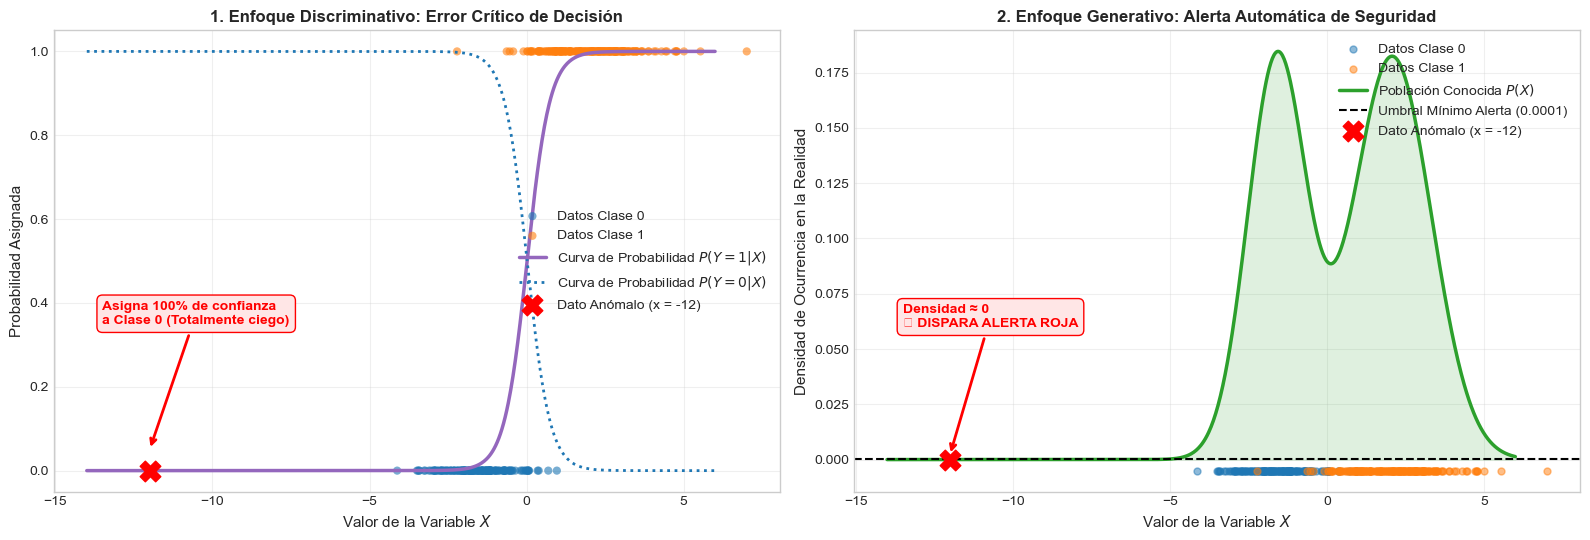

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

# 1. Datos del negocio
np.random.seed(42)
x_c0 = np.random.normal(loc=-1.5, scale=1.0, size=150)  # Ej. Clientes Normales
x_c1 = np.random.normal(loc=2.0, scale=1.3, size=200)   # Ej. Clientes Morosos

X = np.concatenate([x_c0, x_c1]).reshape(-1, 1)
y = np.array([0] * 150 + [1] * 200)

# 2. Ajuste de modelos
lr = LogisticRegression().fit(X, y)
gnb = GaussianNB().fit(X, y)

# 3. Llega un dato en producción sin etiquetar (no sabemos qué es)
x_nuevo = -12.0

# 4. COMPUERTA DE SEGURIDAD GENERATIVA (Cómo alerta el sistema en producción)
prior_0, prior_1 = gnb.class_prior_
densidad_c0 = stats.norm.pdf(x_nuevo, loc=gnb.theta_[0, 0], scale=np.sqrt(gnb.var_[0, 0])) * prior_0
densidad_c1 = stats.norm.pdf(x_nuevo, loc=gnb.theta_[1, 0], scale=np.sqrt(gnb.var_[1, 0])) * prior_1
evidencia_px = densidad_c0 + densidad_c1

UMBRAL_SEGURIDAD = 1e-4  # Cualquier densidad menor a 0.0001 es territorio desconocido

print("================ REPORTE DE DECISIÓN OPERATIVA ================")
print(f"Valor entrante: X = {x_nuevo}")

# A. Diagnóstico Discriminativo (Ciego)
pred_lr = lr.predict([[x_nuevo]])[0]
prob_lr = lr.predict_proba([[x_nuevo]])[0]
print(f"\n[Regresión Logística]")
print(f"  Predicción: Clase {pred_lr} con confianza del {prob_lr[pred_lr]*100:.2f}%")
print(f"  Veredicto: APROBADO CIEGAMENTE (No sabe que el dato jamás se había visto)")

# B. Diagnóstico Generativo (Consciente de la Población)
print(f"\n[GaussianNB con Filtro de Evidencia P(X)]")
print(f"  Evidencia P(X): {evidencia_px:.2e} (Umbral de negocio: {UMBRAL_SEGURIDAD})")

if evidencia_px < UMBRAL_SEGURIDAD:
    print("  Veredicto: 🚨 ALERTA ROJA: ANOMALÍA DETECTADA (Fuera de Distribución)")
    print("  Acción: Transacción congelada. Requiere auditoría humana antes de clasificar.")
else:
    pred_gnb = gnb.predict([[x_nuevo]])[0]
    print(f"  Veredicto: Operación normal. Clasificado como Clase {pred_gnb}")
print("================================================================\n")

# 5. Visualización Comparativa
x_grid = np.linspace(-14, 6, 800).reshape(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# --- PANEL 1: REGRESIÓN LOGÍSTICA ---
axes[0].scatter(x_c0, np.zeros_like(x_c0), color='#1f77b4', alpha=0.6, edgecolors='none', s=35, label='Datos Clase 0')
axes[0].scatter(x_c1, np.ones_like(x_c1), color='#ff7f0e', alpha=0.6, edgecolors='none', s=35, label='Datos Clase 1')
axes[0].plot(x_grid, lr.predict_proba(x_grid)[:, 1], color='#9467bd', lw=2.5, label='Curva de Probabilidad $P(Y=1|X)$')
axes[0].plot(x_grid, lr.predict_proba(x_grid)[:, 0], color='#1f77b4', linestyle=':', lw=2, label='Curva de Probabilidad $P(Y=0|X)$')

# Marcar la anomalía
axes[0].scatter([x_nuevo], [0], color='red', s=220, zorder=5, marker='X', label='Dato Anómalo (x = -12)')
axes[0].annotate('Asigna 100% de confianza\na Clase 0 (Totalmente ciego)', 
                 xy=(x_nuevo, 0.05), xytext=(-13.5, 0.35),
                 arrowprops=dict(arrowstyle='->', color='red', lw=2),
                 fontsize=10, fontweight='bold', color='red',
                 bbox=dict(boxstyle='round,pad=0.4', facecolor='#ffe6e6', edgecolor='red'))

axes[0].set_title('1. Enfoque Discriminativo: Error Crítico de Decisión', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Valor de la Variable $X$', fontsize=11)
axes[0].set_ylabel('Probabilidad Asignada', fontsize=11)
axes[0].legend(loc='center right')
axes[0].grid(alpha=0.3)

# --- PANEL 2: GAUSSIAN NAIVE BAYES ---
# Dibujar datos reales agrupados en el eje
axes[1].scatter(x_c0, np.zeros_like(x_c0) - 0.005, color='#1f77b4', alpha=0.5, s=25, label='Datos Clase 0')
axes[1].scatter(x_c1, np.zeros_like(x_c1) - 0.005, color='#ff7f0e', alpha=0.5, s=25, label='Datos Clase 1')

# Densidades conjuntas
pdf_0 = stats.norm.pdf(x_grid.ravel(), loc=gnb.theta_[0, 0], scale=np.sqrt(gnb.var_[0, 0])) * prior_0
pdf_1 = stats.norm.pdf(x_grid.ravel(), loc=gnb.theta_[1, 0], scale=np.sqrt(gnb.var_[1, 0])) * prior_1
px_total = pdf_0 + pdf_1

axes[1].plot(x_grid, px_total, color='#2ca02c', lw=2.5, label='Población Conocida $P(X)$')
axes[1].fill_between(x_grid.ravel(), px_total, color='#2ca02c', alpha=0.15)
axes[1].axhline(UMBRAL_SEGURIDAD, color='black', linestyle='--', lw=1.5, label=f'Umbral Mínimo Alerta ({UMBRAL_SEGURIDAD})')

# Marcar la anomalía en el desierto de datos
axes[1].scatter([x_nuevo], [0], color='red', s=220, zorder=5, marker='X', label='Dato Anómalo (x = -12)')
axes[1].annotate('Densidad ≈ 0\n🚨 DISPARA ALERTA ROJA', 
                 xy=(x_nuevo, 0.002), xytext=(-13.5, 0.06),
                 arrowprops=dict(arrowstyle='->', color='red', lw=2),
                 fontsize=10, fontweight='bold', color='red',
                 bbox=dict(boxstyle='round,pad=0.4', facecolor='#ffe6e6', edgecolor='red'))

axes[1].set_title('2. Enfoque Generativo: Alerta Automática de Seguridad', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Valor de la Variable $X$', fontsize=11)
axes[1].set_ylabel('Densidad de Ocurrencia en la Realidad', fontsize=11)
axes[1].legend(loc='upper right')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

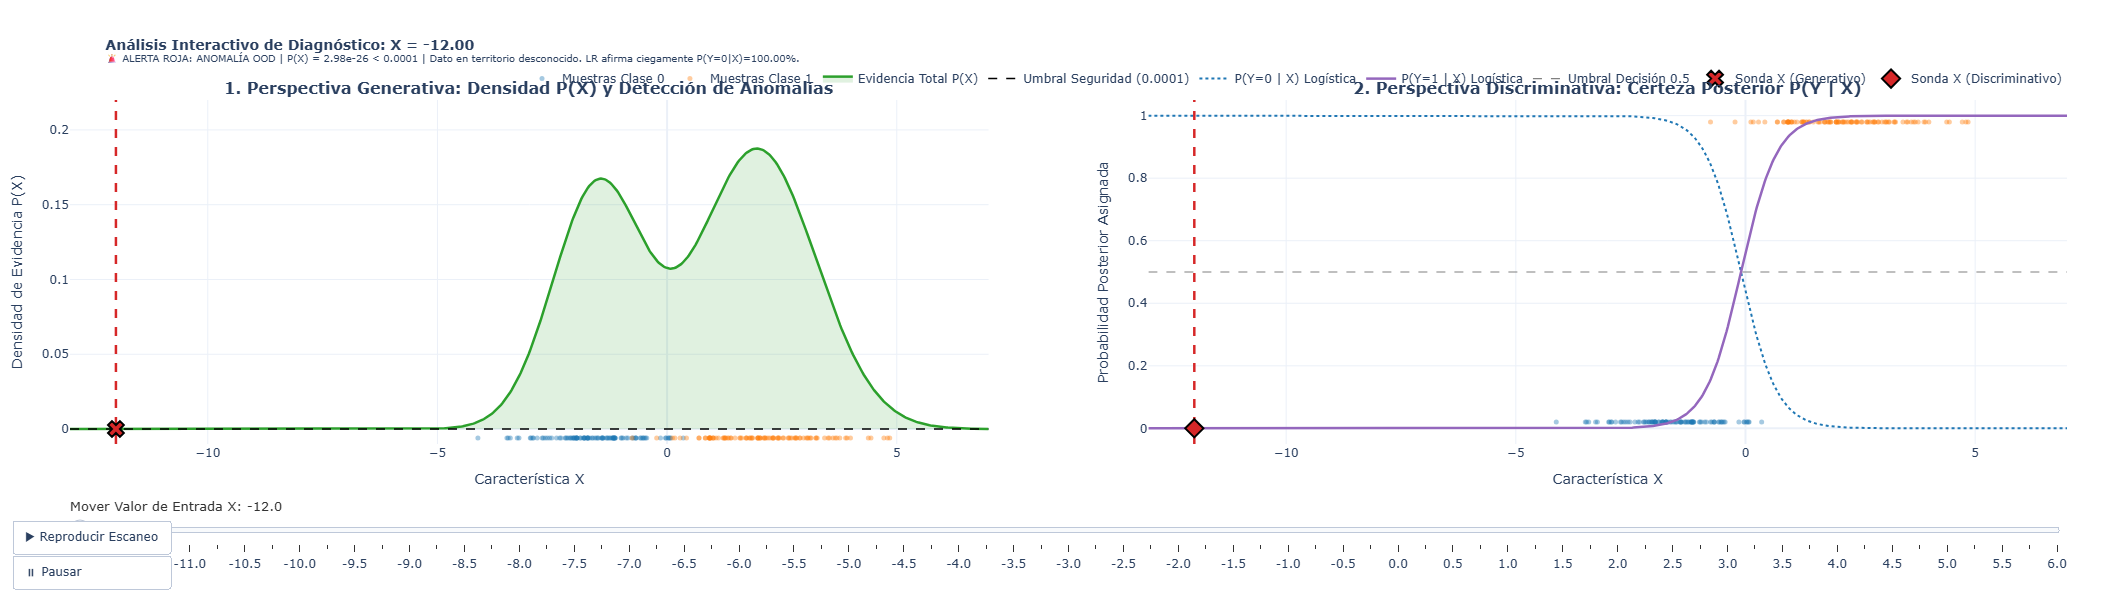

True

In [12]:
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

# ==============================================================================
# 1. GENERACIÓN DE DATOS SINTÉTICOS Y ENTRENAMIENTO DE MODELOS
# ==============================================================================
np.random.seed(42)

# Clase 0: Clientes/Transacciones Normales (N=300, media=-1.5, desv=1.0)
x_c0 = np.random.normal(loc=-1.5, scale=1.0, size=300)
# Clase 1: Clientes Morosos/Riesgosos (N=450, media=2.0, desv=1.3)
x_c1 = np.random.normal(loc=2.0, scale=1.3, size=450)

X = np.concatenate([x_c0, x_c1]).reshape(-1, 1)
y = np.array([0] * 300 + [1] * 450)

# Ajuste de modelos
lr = LogisticRegression().fit(X, y)
gnb = GaussianNB().fit(X, y)

# Parámetros generativos aprendidos
prior_0, prior_1 = gnb.class_prior_
mu_0, var_0 = gnb.theta_[0, 0], gnb.var_[0, 0]
mu_1, var_1 = gnb.theta_[1, 0], gnb.var_[1, 0]
UMBRAL_SEGURIDAD = 1e-4

# Malla global de evaluación continua
x_grid = np.linspace(-13, 7, 700)
pdf_0 = stats.norm.pdf(x_grid, loc=mu_0, scale=np.sqrt(var_0)) * prior_0
pdf_1 = stats.norm.pdf(x_grid, loc=mu_1, scale=np.sqrt(var_1)) * prior_1
px_grid = pdf_0 + pdf_1

prob_lr_c1 = lr.predict_proba(x_grid.reshape(-1, 1))[:, 1]
prob_lr_c0 = lr.predict_proba(x_grid.reshape(-1, 1))[:, 0]

# ==============================================================================
# 2. DEFINICIÓN DEL SLIDER INTERACTIVO Y ESTADOS DINÁMICOS
# ==============================================================================
x_test_points = np.linspace(-12.0, 6.0, 73)  # Pasos de 0.25 unidades

def diagnosticar_punto(x_val):
    dens_c0 = stats.norm.pdf(x_val, loc=mu_0, scale=np.sqrt(var_0)) * prior_0
    dens_c1 = stats.norm.pdf(x_val, loc=mu_1, scale=np.sqrt(var_1)) * prior_1
    px = dens_c0 + dens_c1
    p_lr_1 = lr.predict_proba([[x_val]])[0, 1]
    p_lr_0 = 1.0 - p_lr_1

    if px < UMBRAL_SEGURIDAD:
        color_badge = "#d62728"  # Rojo
        estado = f"🚨 ALERTA ROJA: ANOMALÍA OOD | P(X) = {px:.2e} < {UMBRAL_SEGURIDAD}"
        desc = f"Dato en territorio desconocido. LR afirma ciegamente P(Y={0 if p_lr_0 > 0.5 else 1}|X)={max(p_lr_0, p_lr_1)*100:.2f}%."
    elif abs(p_lr_1 - 0.5) < 0.12:
        color_badge = "#ff7f0e"  # Naranja
        estado = f"⚠️ ZONA FRONTERA DE DECISIÓN | P(X) = {px:.4f} (Población Válida)"
        desc = f"Incertidumbre de clasificación natural: P(Y=1|X)={p_lr_1*100:.1f}% vs P(Y=0|X)={p_lr_0*100:.1f}%."
    elif p_lr_1 >= 0.5:
        color_badge = "#2ca02c"  # Verde
        estado = f"🟢 OPERACIÓN NORMAL (CLASE 1) | P(X) = {px:.4f}"
        desc = f"Evidencia histórica sólida. Modelo asigna Clase 1 con {p_lr_1*100:.2f}% de certeza."
    else:
        color_badge = "#1f77b4"  # Azul
        estado = f"🔵 OPERACIÓN NORMAL (CLASE 0) | P(X) = {px:.4f}"
        desc = f"Evidencia histórica sólida. Modelo asigna Clase 0 con {p_lr_0*100:.2f}% de certeza."

    return px, p_lr_0, p_lr_1, estado, desc, color_badge

# ==============================================================================
# 3. CONSTRUCCIÓN DE LA FIGURA INTERACTIVA (PLOTLY)
# ==============================================================================
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=(
        "<b>1. Perspectiva Generativa: Densidad P(X) y Detección de Anomalías</b>",
        "<b>2. Perspectiva Discriminativa: Certeza Posterior P(Y | X)</b>"
    ),
    horizontal_spacing=0.08
)

# --- PANEL 1: TRAZAS ESTÁTICAS (GENERATIVO) ---
fig.add_trace(go.Scatter(
    x=x_c0[:100], y=np.zeros(100) - 0.006, mode='markers',
    marker=dict(color='#1f77b4', size=5, opacity=0.4),
    name='Muestras Clase 0', showlegend=True
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=x_c1[:100], y=np.zeros(100) - 0.006, mode='markers',
    marker=dict(color='#ff7f0e', size=5, opacity=0.4),
    name='Muestras Clase 1', showlegend=True
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=x_grid, y=px_grid, mode='lines', line=dict(color='#2ca02c', width=2.5),
    fill='tozeroy', fillcolor='rgba(44, 160, 44, 0.15)',
    name='Evidencia Total P(X)', hovertemplate="X: %{x:.2f}<br>P(X): %{y:.4f}<extra></extra>"
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=[x_grid[0], x_grid[-1]], y=[UMBRAL_SEGURIDAD, UMBRAL_SEGURIDAD],
    mode='lines', line=dict(color='black', width=1.5, dash='dash'),
    name=f'Umbral Seguridad ({UMBRAL_SEGURIDAD})'
), row=1, col=1)

# --- PANEL 2: TRAZAS ESTÁTICAS (DISCRIMINATIVO) ---
fig.add_trace(go.Scatter(
    x=x_c0[:100], y=np.zeros(100) + 0.02, mode='markers',
    marker=dict(color='#1f77b4', size=5, opacity=0.4), showlegend=False
), row=1, col=2)

fig.add_trace(go.Scatter(
    x=x_c1[:100], y=np.ones(100) - 0.02, mode='markers',
    marker=dict(color='#ff7f0e', size=5, opacity=0.4), showlegend=False
), row=1, col=2)

fig.add_trace(go.Scatter(
    x=x_grid, y=prob_lr_c0, mode='lines', line=dict(color='#1f77b4', width=2, dash='dot'),
    name='P(Y=0 | X) Logística'
), row=1, col=2)

fig.add_trace(go.Scatter(
    x=x_grid, y=prob_lr_c1, mode='lines', line=dict(color='#9467bd', width=2.5),
    name='P(Y=1 | X) Logística'
), row=1, col=2)

fig.add_trace(go.Scatter(
    x=[x_grid[0], x_grid[-1]], y=[0.5, 0.5], mode='lines',
    line=dict(color='gray', width=1.2, dash='dash'), name='Umbral Decisión 0.5'
), row=1, col=2)

# --- TRAZAS DINÁMICAS (ÍNDICES 8, 9, 10, 11) ---
x_init = x_test_points[0]
px_init, p0_init, p1_init, est_init, desc_init, col_init = diagnosticar_punto(x_init)

fig.add_trace(go.Scatter(
    x=[x_init, x_init], y=[-0.01, 0.22], mode='lines',
    line=dict(color=col_init, width=2.5, dash='dash'), showlegend=False
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=[x_init], y=[px_init], mode='markers',
    marker=dict(color=col_init, size=14, symbol='x', line=dict(width=2, color='black')),
    name='Sonda X (Generativo)', hovertemplate="X: %{x:.2f}<br>P(X): %{y:.2e}<extra></extra>"
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=[x_init, x_init], y=[-0.05, 1.05], mode='lines',
    line=dict(color=col_init, width=2.5, dash='dash'), showlegend=False
), row=1, col=2)

fig.add_trace(go.Scatter(
    x=[x_init], y=[p1_init], mode='markers',
    marker=dict(color=col_init, size=14, symbol='diamond', line=dict(width=2, color='black')),
    name='Sonda X (Discriminativo)', hovertemplate="X: %{x:.2f}<br>P(Y=1|X): %{y:.4f}<extra></extra>"
), row=1, col=2)

# ==============================================================================
# 4. CONSTRUCCIÓN DE FRAMES Y PASOS DEL SLIDER
# ==============================================================================
frames = []
steps = []

for x_val in x_test_points:
    px_v, p0_v, p1_v, estado_v, desc_v, col_v = diagnosticar_punto(x_val)
    f_name = f"{x_val:.2f}"

    frame = go.Frame(
        name=f_name,
        data=[
            # Actualiza traza 8 (línea vertical Panel 1)
            go.Scatter(x=[x_val, x_val], y=[-0.01, 0.22], line=dict(color=col_v, width=2.5, dash='dash')),
            # Actualiza traza 9 (marcador Panel 1)
            go.Scatter(x=[x_val], y=[px_v], marker=dict(color=col_v, size=14, symbol='x')),
            # Actualiza traza 10 (línea vertical Panel 2)
            go.Scatter(x=[x_val, x_val], y=[-0.05, 1.05], line=dict(color=col_v, width=2.5, dash='dash')),
            # Actualiza traza 11 (marcador Panel 2)
            go.Scatter(x=[x_val], y=[p1_v], marker=dict(color=col_v, size=14, symbol='diamond'))
        ],
        traces=[8, 9, 10, 11],
        layout=go.Layout(
            title_text=f"<b>Análisis Interactivo de Diagnóstico: X = {x_val:.2f}</b><br><sup>{estado_v} | {desc_v}</sup>"
        )
    )
    frames.append(frame)

    step = dict(
        method="animate",
        args=[
            [f_name],
            dict(
                mode="immediate",
                frame=dict(duration=0, redraw=True),
                transition=dict(duration=0)
            )
        ],
        label=f"{x_val:.1f}"
    )
    steps.append(step)

fig.frames = frames

# ==============================================================================
# 5. CONFIGURACIÓN DEL LAYOUT Y CONTROLES DEL DASHBOARD
# ==============================================================================
fig.update_layout(
    title=dict(
        text=f"<b>Análisis Interactivo de Diagnóstico: X = {x_init:.2f}</b><br><sup>{est_init} | {desc_init}</sup>",
        font=dict(size=14)
    ),
    sliders=[dict(
        active=0,
        currentvalue=dict(prefix="Mover Valor de Entrada X: ", font=dict(size=13, color="#333")),
        pad=dict(t=50, b=20),
        steps=steps
    )],
    updatemenus=[dict(
        type="buttons",
        showactive=False,
        x=0.05, y=-0.22,
        buttons=[
            dict(
                label="▶ Reproducir Escaneo",
                method="animate",
                args=[None, dict(frame=dict(duration=120, redraw=True), fromcurrent=True, transition=dict(duration=0))]
            ),
            dict(
                label="⏸ Pausar",
                method="animate",
                args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate", transition=dict(duration=0))]
            )
        ]
    )],
    template="plotly_white",
    height=600,
    margin=dict(t=100, b=100, l=60, r=40),
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)

fig.update_xaxes(title_text="Característica X", range=[-13, 7], row=1, col=1)
fig.update_yaxes(title_text="Densidad de Evidencia P(X)", range=[-0.01, 0.22], row=1, col=1)

fig.update_xaxes(title_text="Característica X", range=[-13, 7], row=1, col=2)
fig.update_yaxes(title_text="Probabilidad Posterior Asignada", range=[-0.05, 1.05], row=1, col=2)

# Exportar como archivo independiente y abrir en navegador
fig.write_html("dashboard_generativo_vs_discriminativo.html")
fig.show()

import webbrowser
webbrowser.open("dashboard_generativo_vs_discriminativo.html")

---

## 2. El Teorema de Bayes Aplicado a Clasificación: Cronología del Conocimiento

### Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
Imagina dos situaciones cotidianas:
1. **Filtro de Correo:** ¿Cuál es la probabilidad de que un correo entrante sea *Spam* **antes de abrirlo** (solo sabiendo estadísticas globales de tu bandeja), frente a la probabilidad **después de abrirlo** y observar que contiene las palabras *"Gana bitcoins gratis"*?
2. **La Trampa de la Tasa Base (Fraude / Diagnóstico Clínico):** Un banco sabe que solo **1 de cada 1,000 transacciones es fraudulenta** ($P(\text{Fraude}) = 0.001$). Implementan una regla detectora con **99% de sensibilidad** (si hay fraude, la alarma suena el 99% de las veces) y solo **1% de falsas alarmas** en transacciones legítimas. Si suena la alarma para un cliente, ¿la probabilidad de que sea fraude es del 99%? **¡No! Es apenas del 9%.** Confundir $P(\text{Alarma} \mid \text{Fraude})$ con $P(\text{Fraude} \mid \text{Alarma})$ se conoce como la **Falacia de la Tasa Base** (o *Falacia del Fiscal*) y cuesta millones de dólares en bloqueos erróneos de tarjetas.

---

### Paso 2: Formalismo Matemático Riguroso

Sea $(\Omega, \mathcal{F}, P)$ un espacio de probabilidad, $\mathbf{X}: \Omega \to \mathbb{R}^D$ el vector aleatorio de características observadas ($\mathbf{x} = (x_1, x_2, \dots, x_D)^\top$) y $Y: \Omega \to \mathcal{Y} = \{c_1, \dots, c_C\}$ la variable aleatoria discreta que denota la clase verdadera. Por definición de probabilidad condicional:

$$P(Y = c_k \mid \mathbf{X} = \mathbf{x}) = \frac{P(Y = c_k, \mathbf{X} = \mathbf{x})}{P(\mathbf{X} = \mathbf{x})} = \frac{P(Y = c_k) \cdot P(\mathbf{X} = \mathbf{x} \mid Y = c_k)}{\sum_{j=1}^{C} P(Y = c_j) \cdot P(\mathbf{X} = \mathbf{x} \mid Y = c_j)}$$

**Definición explícita de notación:**
* $k \in \{1, \dots, C\}$: Subíndice de la clase candidata que estamos evaluando.
* $j \in \{1, \dots, C\}$: Índice mudo que recorre la partición exhaustiva y mutuamente excluyente del espacio de clases en el denominador (Ley de la Probabilidad Total).
* $\mathbf{x} \in \mathbb{R}^D$: Vector de evidencia empírica observada en la instancia actual.

---

### Paso 3: Traducción "En Palabras Claras" (Cronología Epistemológica: Antes vs. Después)

$$\underbrace{P(C_k \mid \mathbf{x})}_{\substack{\text{4. A Posteriori} \\ \text{(Después de ver } \mathbf{x}\text{)}}} = \frac{\overbrace{P(C_k)}^{\substack{\text{1. A Priori} \\ \text{(Antes de ver } \mathbf{x}\text{)}}} \times \overbrace{P(\mathbf{x} \mid C_k)}^{\substack{\text{2. Verosimilitud} \\ \text{(Generador de datos)}}}}{\underbrace{\sum_{j=1}^{C} P(\mathbf{x} \mid C_j)P(C_j)}_{\substack{\text{3. Evidencia Marginal} \\ \text{(Constante Normalizadora)}}}}$$

| Etapa Temporal | Término Matemático | Nombre Técnico | ¿Qué mide en palabras claras? | ¿De dónde sale en los datos? | ¿Qué pasa en casos extremos ($0$ o $\infty$)? |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **1. Estado Previo (Antes de observar $\mathbf{x}$)** | $P(C_k)$ | **A Priori (*Prior*)** | Nuestra creencia inicial o prevalencia histórica en la población antes de mirar cualquier característica de la instancia actual. | Frecuencia relativa histórica: $N_k / N$ (o definida por conocimiento experto del negocio). | Si $P(C_k) = 0$, la clase $C_k$ queda vetada para siempre ($P(C_k \mid \mathbf{x}) = 0$) sin importar cuánta evidencia a favor traiga $\mathbf{x}$. |
| **2. Durante la Observación (El Generador)** | $P(\mathbf{x} \mid C_k)$ | **Verosimilitud (*Likelihood*)** | **¡Ojo al orden!** Si supiéramos con certeza absoluta que la clase verdadera es $C_k$, ¿qué tan probable o compatible sería observar exactamente el vector $\mathbf{x}$? | Se estima ajustando histogramas, conteos o campanas gaussianas dentro del subconjunto de entrenamiento de la clase $C_k$. | Si vale $0$ (ej. una palabra nunca vista en entrenamiento), anula todo el numerador. Se corrige con *Laplace Smoothing* o `var_smoothing`. |
| **3. Factor de Escala Global** | $P(\mathbf{x}) = \sum_{j=1}^C P(\mathbf{x} \mid C_j)P(C_j)$ | **Evidencia Marginal** | La probabilidad total de toparnos con las características $\mathbf{x}$ en el universo, sumando todos los caminos posibles (Ley de Probabilidad Total). | Suma de los numeradores calculados para todas las $C$ clases. | **En optimización MAP ($\arg\max_k$) se ignora** porque divide por el mismo número exacto a todas las clases candidatas. |
| **4. Estado Actualizado (Después de ver $\mathbf{x}$)** | $P(C_k \mid \mathbf{x})$ | **A Posteriori (*Posterior*)** | Nuestra creencia refinada y actualizada sobre la clase $C_k$ tras ponderar la creencia inicial con la evidencia empírica observada. | Resultado final de `.predict_proba(X)`. | Es una distribución válida $\in [0, 1]$ tal que $\sum_{k=1}^C P(C_k \mid \mathbf{x}) = 1$. |

####  Mini-Caso Analítico Obligatorio: Desmontando la Falacia de la Tasa Base
Sea $C_1 = \text{Fraude}$ y $C_0 = \text{Legítima}$ con una tasa base muy baja en producción: $P(C_1) = 0.001$ ($0.1\%$) y $P(C_0) = 0.999$ ($99.9\%$).  
Contamos con una señal de alerta $X = 1$ (transacción internacional nocturna) cuyas métricas de laboratorio son:
* **Sensibilidad (Verosimilitud en Fraude):** $P(X=1 \mid C_1) = 0.99$ ($99\%$).
* **Tasa de Falsos Positivos (Verosimilitud en Legítima):** $P(X=1 \mid C_0) = 0.01$ ($1\%$, lo que equivale a $99\%$ de especificidad).

Calculemos el estado actualizado **A Posteriori** $P(C_1 \mid X=1)$ cuando se activa la alerta:
1. **Numerador Fraude:** $P(C_1) \cdot P(X=1 \mid C_1) = 0.001 \times 0.99 = 0.00099$.
2. **Numerador Legítima (Falsas alarmas):** $P(C_0) \cdot P(X=1 \mid C_0) = 0.999 \times 0.01 = 0.00999$.
3. **Evidencia Marginal $P(X=1)$:** $0.00099 + 0.00999 = 0.01098$.
4. **Posterior real:**
   $$P(\text{Fraude} \mid X=1) = \frac{0.00099}{0.00099 + 0.00999} = \frac{0.00099}{0.01098} \approx 0.09016 \; (\mathbf{9.02\%})$$

> **Lección Crítica de Ingeniería:** Aunque el detector tiene $99\%$ de precisión condicional ($P(X=1 \mid C_1) = 0.99$), como las transacciones legítimas superan $999$ a $1$ a los fraudes, el $1\%$ de falsas alarmas sobre la masa legítima ($0.00999$) supera en **10 veces** a los verdaderos fraudes detectados ($0.00099$). Por eso Naive Bayes exige combinar múltiples *features* independientes o un *Prior* bien calibrado antes de bloquear una tarjeta.

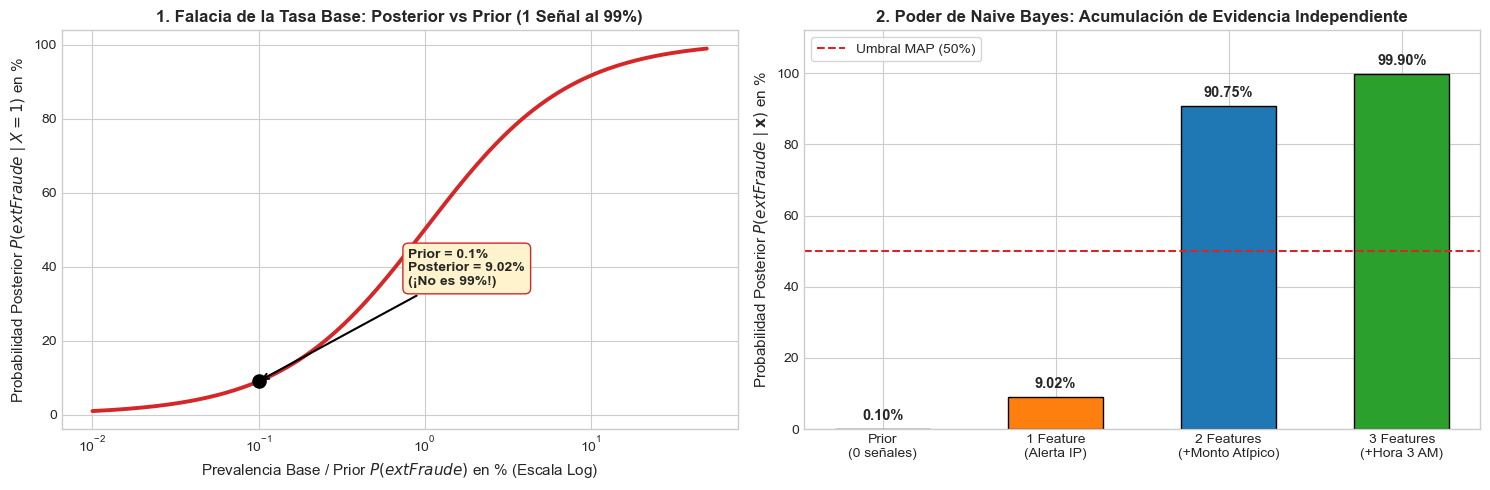

 Conclusión Accionable:
• Con 1 sola feature (Panel 1), bloquear la tarjeta sería un error grave: el 90.98% de las alertas serían clientes legítimos molestos.
• Con 2 features independientes (Panel 2), el posterior del paso 1 (9.02%) se convierte en el nuevo Prior del paso 2, elevando la certeza al 90.75% (¡y al 99.90% con 3 features!).


In [15]:
#  Paso 4: Código, Visualización e Interpretación de Negocio (La Falacia de la Tasa Base y Actualización Secuencial)
prior_fraude = 0.001
prior_legit = 1.0 - prior_fraude

sensibilidad = 0.99        # P(Alerta | Fraude)
falso_positivo = 0.01      # P(Alerta | Legítima)

# Evolución de la probabilidad Posterior al acumular N señales independientes (k = 1, 2, 3 evidencias)
evidencias = [0, 1, 2, 3]
posteriors_evolucion = [prior_fraude]

p_actual = prior_fraude
for k in range(1, 4):
    num_f = p_actual * sensibilidad
    num_l = (1.0 - p_actual) * falso_positivo
    p_actual = num_f / (num_f + num_l)
    posteriors_evolucion.append(p_actual)

# Curva del Posterior en función de la Tasa Base (Prior) para 1 alerta
priors_grid = np.logspace(-4, -0.3, 200)
posteriors_grid = (priors_grid * sensibilidad) / (
    priors_grid * sensibilidad + (1 - priors_grid) * falso_positivo
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: Efecto de la Tasa Base
axes[0].plot(priors_grid * 100, posteriors_grid * 100, color='#d62728', lw=2.8)
axes[0].scatter([prior_fraude * 100], [posteriors_evolucion[1] * 100], color='black', s=90, zorder=5)
axes[0].annotate(
    f'Prior = 0.1%\nPosterior = {posteriors_evolucion[1]*100:.2f}%\n(¡No es 99%!)',
    xy=(prior_fraude * 100, posteriors_evolucion[1] * 100),
    xytext=(0.8, 35),
    arrowprops=dict(arrowstyle='->', color='black', lw=1.5),
    fontsize=10, fontweight='bold', bbox=dict(boxstyle='round,pad=0.4', facecolor='#fff3cd', edgecolor='#d62728')
)
axes[0].set_xscale('log')
axes[0].set_title('1. Falacia de la Tasa Base: Posterior vs Prior (1 Señal al 99%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prevalencia Base / Prior $P(\text{Fraude})$ en % (Escala Log)', fontsize=11)
axes[0].set_ylabel('Probabilidad Posterior $P(\text{Fraude} \mid X=1)$ en %', fontsize=11)

# Panel 2: Actualización Bayesiana Secuencial con Múltiples Features (Cómo rescata Naive Bayes la precisión)
etiquetas_ev = ['Prior\n(0 señales)', '1 Feature\n(Alerta IP)', '2 Features\n(+Monto Atípico)', '3 Features\n(+Hora 3 AM)']
barras = axes[1].bar(etiquetas_ev, [p * 100 for p in posteriors_evolucion], color=['#7f7f7f', '#ff7f0e', '#1f77b4', '#2ca02c'], edgecolor='k', width=0.55)
axes[1].axhline(50, color='#d62728', linestyle='--', lw=1.5, label='Umbral MAP (50%)')
for bar, p_val in zip(barras, posteriors_evolucion):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2.5, f'{p_val*100:.2f}%', ha='center', fontweight='bold', fontsize=10.5)

axes[1].set_ylim(0, 112)
axes[1].set_title('2. Poder de Naive Bayes: Acumulación de Evidencia Independiente', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Probabilidad Posterior $P(\text{Fraude} \mid \mathbf{x})$ en %', fontsize=11)
axes[1].legend(loc='upper left', frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

print(" Conclusión Accionable:")
print(f"• Con 1 sola feature (Panel 1), bloquear la tarjeta sería un error grave: el 90.98% de las alertas serían clientes legítimos molestos.")
print(f"• Con 2 features independientes (Panel 2), el posterior del paso 1 (9.02%) se convierte en el nuevo Prior del paso 2, elevando la certeza al {posteriors_evolucion[2]*100:.2f}% (¡y al {posteriors_evolucion[3]*100:.2f}% con 3 features!).")

---

## 3. El Supuesto de Independencia Condicional: Qué es, Qué NO es y Complejidad Paramétrica

### Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
Supongamos que queremos diagnosticar si un paciente tiene **Gripe ($C = 1$)** o está **Sano ($C = 0$)** observando dos síntomas: **Fiebre ($X_1$)** y **Dolor Muscular ($X_2$)**.
* Si tomas a 10,000 personas al azar en la calle, ¿la Fiebre y el Dolor Muscular son independientes? **¡Por supuesto que NO!** Quien tiene fiebre tiene muchísima más probabilidad de tener dolor muscular ($P(X_1, X_2) \neq P(X_1)P(X_2)$).
* Pero, **si ya sabemos con certeza que el paciente tiene Gripe ($C=1$)** (la causa común que origina ambos síntomas ya está fijada), saber que tiene fiebre ya no nos da información extra sobre el mecanismo biológico de su dolor muscular.

Además, si en lugar de 2 síntomas tuviéramos **$D = 100$ características binarias** (ej. 100 palabras en un correo o 100 indicadores financieros), intentar modelar todas las combinaciones posibles requeriría estimar $2^{100} \approx 1.26 \times 10^{30}$ parámetros. ¿Cómo logra Naive Bayes clasificar en **menos de 2 milisegundos** sin desbordar la memoria?

---

###  Paso 2: Formalismo Matemático 

#### A. Distinción Analítica: Independencia Condicional vs. Independencia Marginal
Dos variables aleatorias $X_1$ y $X_2$ son **marginalmente independientes** ($X_1 \perp\!\!\!\perp X_2$) si y solo si:

$$P(X_1 = x_1, X_2 = x_2) = P(X_1 = x_1) \cdot P(X_2 = x_2)$$

Por el contrario, $X_1$ y $X_2$ son **condicionalmente independientes dada la clase $C$** ($X_1 \perp\!\!\!\perp X_2 \mid C$) si y solo si, para cada clase fija $c_k \in \mathcal{Y}$:

$$P(X_1 = x_1, X_2 = x_2 \mid C = c_k) = P(X_1 = x_1 \mid C = c_k) \cdot P(X_2 = x_2 \mid C = c_k)$$

> **Teorema Fundamental (La Independencia Condicional NO implica Independencia Marginal):**  
> Si $X_1 \perp\!\!\!\perp X_2 \mid C$, la distribución conjunta marginal en la población general es:
> $$P(X_1, X_2) = \sum_{k=1}^{C} P(C = c_k) P(X_1, X_2 \mid C = c_k) = \sum_{k=1}^{C} P(C = c_k) P(X_1 \mid C = c_k) P(X_2 \mid C = c_k)$$
> Algebraicamente, la combinación convexa de productos **no es igual** al producto de las combinaciones convexas:
> $$\sum_{k=1}^{C} P(C_k) P(X_1 \mid C_k) P(X_2 \mid C_k) \neq \left( \sum_{k=1}^{C} P(C_k) P(X_1 \mid C_k) \right) \left( \sum_{k=1}^{C} P(C_k) P(X_2 \mid C_k) \right) = P(X_1)P(X_2)$$

#### Diagrama de Red Bayesiana (Estructura de Causa Común / Fork)
```text
          [ Clase Y = c_k ]        <-- Nodo Padre (Causa Común)
           /      |       \
          v       v        v
       ( X_1 )  ( X_2 ) ...( X_D ) <-- Nodos Hijos (Condicionalmente independientes dado Y)
```
* **Sin observar $Y$:** El camino $X_1 \leftarrow Y \rightarrow X_2$ está **abierto** (activo); $X_1$ y $X_2$ están fuertemente correlacionados en el dataset global.
* **Al condicionar en $Y = c_k$:** El nodo $Y$ **bloquea** (*d-separa*) el camino; $X_1$ y $X_2$ se vuelven independientes dentro de cada clase.

#### B. El Cuello de Botella Combinatorio y la Factorización "Naive"
Para calcular la verosimilitud conjunta $P(x_1, x_2, \dots, x_D \mid Y = c_k)$ aplicando la regla de la cadena de probabilidad exacta sin hacer suposiciones adicionales, tendríamos que modelar todas las dependencias cruzadas:

$$P(x_1, x_2, \dots, x_D \mid Y = c_k) = P(x_1 \mid Y=c_k) \cdot P(x_2 \mid x_1, Y=c_k) \cdots P(x_D \mid x_1, \dots, x_{D-1}, Y=c_k)$$

En un problema con $C$ clases y $D$ características discretas con $K$ niveles cada una:
* El número de configuraciones posibles del vector $\mathbf{x}$ es $K^D$, requiriendo estimar **$\mathcal{O}(C \cdot K^D)$ parámetros**.
* Con $C = 2, K = 2, D = 50$, requeriríamos $2 \times (2^{50} - 1) \approx 2.25 \times 10^{15}$ parámetros (imposible de estimar sin caer en sobreajuste por celdas vacías).

Bajo la hipótesis **Naive Bayes** ($X_i \perp\!\!\!\perp X_j \mid Y \; \forall i \neq j$), la distribución conjunta multidimensional se factoriza en el producto de $D$ distribuciones univariadas marginales:

$$P(x_1, x_2, \dots, x_D \mid Y = c_k) = \prod_{j=1}^{D} P(x_j \mid Y = c_k)$$

colapsando la complejidad espacial y computacional de exponencial $\mathcal{O}(C \cdot K^D)$ a **lineal $\mathcal{O}(C \cdot D \cdot K)$**.

---

### 🌉 Paso 3: Traducción "En Palabras Claras" (El Puente Conceptual)

| Concepto / Expresión | ¿Qué asume exactamente? | Impacto en Ingeniería de Datos y Producción |
| :--- | :--- | :--- |
| $P(X_1, X_2) \neq P(X_1)P(X_2)$ | Las variables **sí están correlacionadas** en el dataset completo (porque comparten la clase $Y$ como causa común). | **Error frecuente:** No descartes Naive Bayes solo porque la matriz de correlación `df.corr()` global muestre correlaciones altas; lo que importa es la correlación *dentro* de cada clase. |
| $P(\mathbf{x} \mid C_k) = \prod_{j=1}^D P(x_j \mid C_k)$ | Cada característica $x_j$ aporta su voto de evidencia de forma aislada, sin mirar qué valores tomaron las demás columnas. | Permite entrenar el modelo en **una sola pasada sobre los datos** y evaluar cada columna en paralelo sin invertir matrices de covarianza de tamaño $D \times D$. |

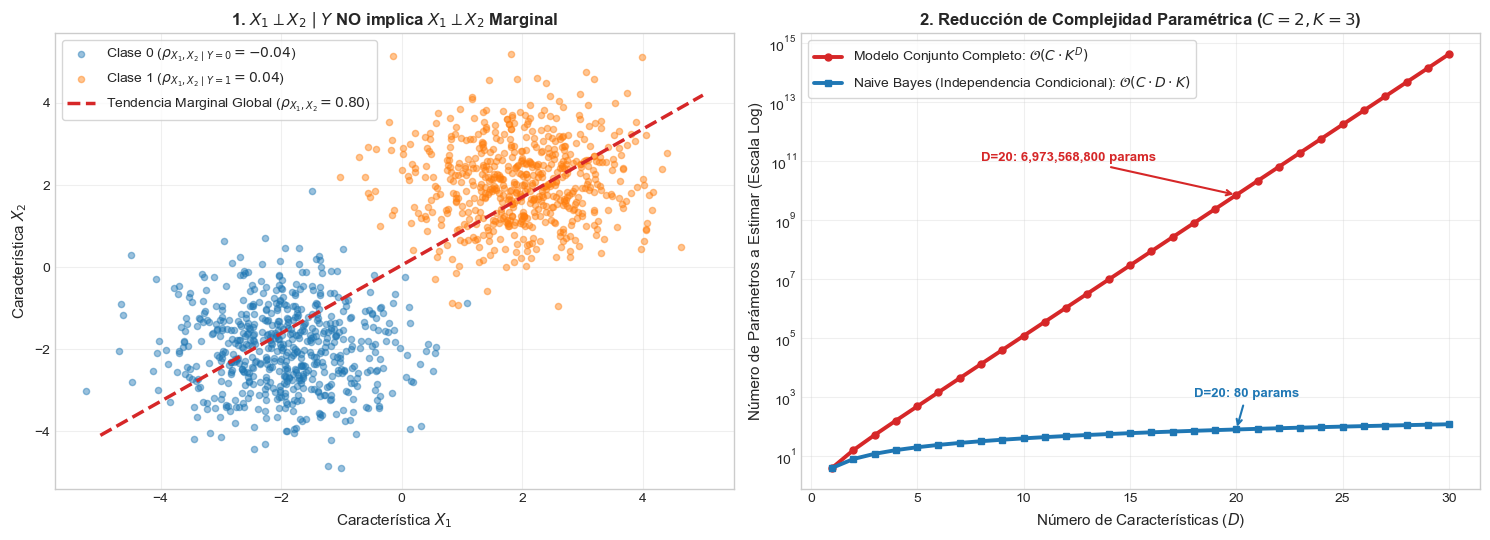

In [17]:


# Paso 4: Código, Visualización e Interpretación (Independencia Condicional != Marginal y Complejidad)
np.random.seed(42)

# 1. Demostración de que X1 y X2 son independientes DENTRO de cada clase, pero correlacionadas GLOBALMENTE
# Clase 0: centrada en (-2, -2) con covarianza diagonal (rho_intra = 0)
X_c0_ind = np.random.multivariate_normal(mean=[-2.0, -2.0], cov=[[1.0, 0.0], [0.0, 1.0]], size=600)
# Clase 1: centrada en (+2, +2) con covarianza diagonal (rho_intra = 0)
X_c1_ind = np.random.multivariate_normal(mean=[2.0, 2.0], cov=[[1.0, 0.0], [0.0, 1.0]], size=600)
X_global = np.vstack([X_c0_ind, X_c1_ind])

rho_c0 = np.corrcoef(X_c0_ind[:, 0], X_c0_ind[:, 1])[0, 1]
rho_c1 = np.corrcoef(X_c1_ind[:, 0], X_c1_ind[:, 1])[0, 1]
rho_global = np.corrcoef(X_global[:, 0], X_global[:, 1])[0, 1]

# 2. Curvas de Complejidad Paramétrica (dtype=float para evitar integer overflow con potencias de 3)
D_vals = np.arange(1, 31, dtype=float)
C, K = 2, 3
params_conjunta = C * (K**D_vals - 1.0)
params_naive = C * D_vals * (K - 1.0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel 1: Independencia Condicional vs Marginal (uso de raw f-strings fr'...')
axes[0].scatter(X_c0_ind[:, 0], X_c0_ind[:, 1], color='#1f77b4', alpha=0.45, s=20, 
                label=fr'Clase 0 ($\rho_{{X_1,X_2 \mid Y=0}} = {rho_c0:.2f}$)')
axes[0].scatter(X_c1_ind[:, 0], X_c1_ind[:, 1], color='#ff7f0e', alpha=0.45, s=20, 
                label=fr'Clase 1 ($\rho_{{X_1,X_2 \mid Y=1}} = {rho_c1:.2f}$)')

# Línea de tendencia marginal global
m_glob, b_glob = np.polyfit(X_global[:, 0], X_global[:, 1], 1)
x_line = np.linspace(-5, 5, 100)
axes[0].plot(x_line, m_glob * x_line + b_glob, color='#d62728', linestyle='--', lw=2.5,
             label=fr'Tendencia Marginal Global ($\rho_{{X_1,X_2}} = {rho_global:.2f}$)')
axes[0].set_title(r'1. $X_1 \perp X_2 \mid Y$ NO implica $X_1 \perp X_2$ Marginal', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Característica $X_1$', fontsize=11)
axes[0].set_ylabel('Característica $X_2$', fontsize=11)
axes[0].legend(frameon=True, facecolor='white', loc='upper left')
axes[0].grid(alpha=0.3)

# Panel 2: Explosión Exponencial vs Crecimiento Lineal
axes[1].plot(D_vals, params_conjunta, color='#d62728', lw=2.8, marker='o', markersize=5,
             label=r'Modelo Conjunto Completo: $\mathcal{O}(C \cdot K^D)$')
axes[1].plot(D_vals, params_naive, color='#1f77b4', lw=2.8, marker='s', markersize=5,
             label=r'Naive Bayes (Independencia Condicional): $\mathcal{O}(C \cdot D \cdot K)$')
axes[1].set_yscale('log')
axes[1].set_title('2. Reducción de Complejidad Paramétrica ($C=2, K=3$)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Número de Características ($D$)', fontsize=11)
axes[1].set_ylabel('Número de Parámetros a Estimar (Escala Log)', fontsize=11)

# Anotaciones con valores limpios sin desbordamiento
axes[1].annotate(f'D=20: {params_conjunta[19]:,.0f} params', xy=(20, params_conjunta[19]),
                 xytext=(8, 1e11), arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.5),
                 fontsize=9.5, fontweight='bold', color='#d62728')
axes[1].annotate(f'D=20: {params_naive[19]:,.0f} params', xy=(20, params_naive[19]),
                 xytext=(18, 1e3), arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5),
                 fontsize=9.5, fontweight='bold', color='#1f77b4')
axes[1].legend(fontsize=10, frameon=True, facecolor='white')
axes[1].grid(alpha=0.3, which='both')

plt.tight_layout()
plt.show()


---

#### 1. Panel Izquierdo: ¿Por qué la Independencia Condicional NO Implica Independencia Marginal?

$$\mathbf{X_1 \perp X_2 \mid Y \centernot\implies X_1 \perp X_2}$$

Un error conceptual muy común al estudiar **Naive Bayes** es pensar que el modelo asume que las variables no tienen ninguna relación entre sí en el mundo real. **Eso es falso.** El supuesto ingenuo (*naive*) se aplica **únicamente dentro de cada clase**.

* **Dentro de cada clase (Independencia Condicional):**
  * Observen la nube azul (**Clase 0**): tiene forma perfectamente circular/esférica ($\rho_{X_1, X_2 \mid Y=0} \approx -0.04$). Saber el valor de $X_1$ no nos aporta ninguna información sobre $X_2$.
  * Observen la nube naranja (**Clase 1**): igualmente circular ($\rho_{X_1, X_2 \mid Y=1} \approx 0.04$).
  * En términos probabilísticos:
    $$P(X_1, X_2 \mid Y = c_k) = P(X_1 \mid Y = c_k) \cdot P(X_2 \mid Y = c_k)$$

* **En la población global (Dependencia Marginal):**
  * Si ocultamos las etiquetas de clase y observamos todos los puntos juntos, la nube combinada forma una diagonal ascendente evidente.
  * La correlación marginal global se dispara a **$\rho_{X_1, X_2} = 0.80$** (línea roja discontinua).

> ** Analogía para Recordar en Examen:**  
> Piensen en $X_1 = \text{Tamaño de zapato}$, $X_2 = \text{Nivel de lectura}$ e $Y = \text{Grado escolar (Primaria vs. Universidad)}$.  
> En la población total, quienes calzan más leen mucho mejor ($\rho$ alto). Pero si controlamos por la clase (ej. fijamos $Y = \text{Universidad}$), el tamaño del pie ya no dice absolutamente nada sobre la capacidad lectora ($\rho \approx 0$).

---

#### 2. Panel Derecho: La Maldición de la Dimensionalidad vs. El Supuesto Ingenuo

Este panel ilustra la justificación computacional e ingenieril de por qué Naive Bayes sigue utilizándose intensivamente en Big Data y sistemas distribuidos.

Supongamos que clasificamos instancias en $C = 2$ clases, donde cada observación tiene $D$ características discretas con $K = 3$ categorías cada una (por ejemplo: `Bajo`, `Medio`, `Alto`):

| Métrica / Enfoque | Modelo Conjunto Completo $P(\mathbf{X} \mid Y)$ | Naive Bayes $P(X_1 \mid Y)\cdots P(X_D \mid Y)$ |
| :--- | :--- | :--- |
| **Complejidad** | $\mathcal{O}(C \cdot K^D)$ *(Exponencial)* | $\mathcal{O}(C \cdot D \cdot K)$ *(Lineal)* |
| **Fórmula de parámetros** | $C \cdot (K^D - 1)$ | $C \cdot D \cdot (K - 1)$ |
| **Para $D = 5$ variables** | $2 \cdot (3^5 - 1) = \mathbf{484}$ params | $2 \cdot 5 \cdot (3 - 1) = \mathbf{20}$ params |
| **Para $D = 20$ variables** | $2 \cdot (3^{20} - 1) \approx \mathbf{6,973,568,800}$ params | $2 \cdot 20 \cdot (3 - 1) = \mathbf{80}$ params |

##### Conclusiones Técnicas de Negocio:

1. **Intratabilidad Estadística:** Con $D = 20$, el modelo completo exige estimar **casi 7 mil millones de probabilidades conjuntas**. Ninguna empresa tiene suficientes datos históricos para llenar esa tabla multidimensional; la inmensa mayoría de combinaciones tendrían $0$ observaciones (frecuencias nulas y varianza infinita).
2. **Eficiencia Extrema:** Al asumir independencia condicional, Naive Bayes reduce el problema a estimar únicamente **80 parámetros**.
3. **Escalabilidad en Producción:** Permite entrenar clasificadores con miles de dimensiones (como clasificación de texto o genómica) en una sola pasada lineal $\mathcal{O}(N \cdot D)$, sin riesgo de desbordamiento de memoria ni sobreajuste severo.

---

## 4. Regla MAP y el Espacio Logarítmico (*Log-Space Trick*)

###  Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
Imagina que estás clasificando un documento legal o una transacción con **$D = 1,500$ características**. En NLP, la probabilidad de que aparezca una palabra específica en un documento es pequeña, digamos $P(x_j \mid C_k) \approx 0.005$.  
Si programas la ecuación de Bayes multiplicando directamente esas $1,500$ probabilidades en tu servidor:
$$0.005 \times 0.005 \times \dots \times 0.005 = (0.005)^{1500} \approx 10^{-3451}$$
Sin embargo, el procesador de tu computadora (estándar IEEE 754 `float64`) **colapsa a `0.0` absoluto** para cualquier número menor a $2.22 \times 10^{-308}$. Como resultado, el numerador da `0.0`, el denominador da `0.0`, y tu API en producción devuelve `NaN` (*Not a Number*). ¿Cómo evaluamos decenas de miles de *features* sin sufrir un colapso numérico?

---

### 📐 Paso 2: Formalismo Matemático Riguroso

#### Deducción de la Regla de Decisión MAP
Para clasificar una nueva observación $\mathbf{x}$, elegimos la clase $\hat{y}$ que maximiza la probabilidad a posteriori, criterio conocido como **Maximum A Posteriori (MAP)**:

$$\hat{y}_{\text{MAP}} = \underset{c_k \in \mathcal{Y}}{\arg\max} \; P(Y = c_k \mid \mathbf{X} = \mathbf{x}) = \underset{c_k \in \mathcal{Y}}{\arg\max} \; \frac{P(Y = c_k) \prod_{j=1}^{D} P(x_j \mid Y = c_k)}{P(\mathbf{X} = \mathbf{x})}$$

Dado que la evidencia marginal $P(\mathbf{X} = \mathbf{x}) > 0$ es una constante de escalamiento **idéntica para todas las clases candidatas $c_k$**, no altera la ubicación del máximo en la operación $\arg\max$ y puede descartarse:

$$\hat{y}_{\text{MAP}} = \underset{c_k \in \mathcal{Y}}{\arg\max} \; \left[ P(Y = c_k) \prod_{j=1}^{D} P(x_j \mid Y = c_k) \right]$$

#### Transformación al Espacio Logarítmico
Como la función logaritmo natural $\ln: (0, \infty) \to (-\infty, \infty)$ es **estrictamente creciente y monótona** ($a > b \iff \ln(a) > \ln(b)$), aplicar $\ln(\cdot)$ preserva intacto el argumento que maximiza la función objetivo:

$$\hat{y}_{\text{MAP}} = \underset{c_k \in \mathcal{Y}}{\arg\max} \; \ln \left( P(Y = c_k) \prod_{j=1}^{D} P(x_j \mid Y = c_k) \right)$$

Por el homomorfismo logarítmico ($\ln(a \cdot b) = \ln a + \ln b$), el productorio propenso a *underflow* se transforma en una **suma de log-verosimilitudes (*Joint Log-Likelihood*, $\ell_k(\mathbf{x})$)** numéricamente estable:

$$\hat{y}_{\text{MAP}} = \underset{c_k \in \mathcal{Y}}{\arg\max} \; \underbrace{\left[ \ln P(Y = c_k) + \sum_{j=1}^{D} \ln P(x_j \mid Y = c_k) \right]}_{\ell_k(\mathbf{x})}$$

#### Recuperación de Probabilidades Exactas: El Truco *Log-Sum-Exp*
Cuando necesitamos devolver probabilidades calibradas en $[0, 1]$ (método `.predict_proba(X)`), debemos invertir el logaritmo sobre $\ell_k(\mathbf{x})$. Si calculamos directamente $e^{\ell_k}$ cuando $\ell_k = -3500$, volveríamos a caer en $e^{-3500} = 0.0$. Para evitarlo, definimos el máximo puntaje entre las clases $M(\mathbf{x}) = \max_{m \in \{1,\dots,C\}} \ell_m(\mathbf{x})$ y multiplicamos numerador y denominador por $e^{-M(\mathbf{x})}$:

$$P(Y = c_k \mid \mathbf{x}) = \frac{e^{\ell_k(\mathbf{x})}}{\sum_{m=1}^{C} e^{\ell_m(\mathbf{x})}} = \frac{e^{\ell_k(\mathbf{x}) - M(\mathbf{x})}}{\sum_{m=1}^{C} e^{\ell_m(\mathbf{x}) - M(\mathbf{x})}}$$

De esta forma, la clase ganadora tiene exponente $0$ ($e^0 = 1$), garantizando que el denominador sea siempre $\ge 1.0$ y eliminando por completo el riesgo de división `0 / 0`.

---

### Paso 3: Traducción "En Palabras Claras" (El Puente Conceptual)

| Operación Matemática | En el Espacio Crudo $[0, 1]$ | En el Espacio Logarítmico $(-\infty, 0]$ | Ventaja Computacional en Hardware |
| :--- | :--- | :--- | :--- |
| **Acumular evidencia de $D$ variables** | Multiplicación: $p_1 \times p_2 \times \dots \times p_D$ | Suma: $\ln p_1 + \ln p_2 + \dots + \ln p_D$ | La suma en CPU/GPU es más rápida y convierte números de $10^{-3000}$ en sumas manejables como $-6907.75$. |
| **Normalizar probabilidades posteriores** | División directa: $\frac{\text{Num}_k}{\sum_m \text{Num}_m}$ | **Log-Sum-Exp:** Restar $M = \max_m \ell_m$ antes de aplicar `np.exp()` | Garantiza que al menos un término valga exactamente $e^0 = 1.0$, blindando el código contra `NaN`. |

In [18]:
#  Paso 4: Demostración Empírica del Underflow Numérico en float64 vs Estabilidad en Log-Space
dimensiones = [10, 100, 500, 1000, 1500]
prob_media_feature = 0.005  # Probabilidad típica de una palabra en NLP

print(f"{'Dimensión (D)':<15} | {'Producto Directo (float64)':<28} | {'Suma Logarítmica ln P(X,Y)':<25}")
print("-" * 75)

for d in dimensiones:
    probs = np.full(d, prob_media_feature, dtype=np.float64)
    prod_directo = np.prod(probs)
    suma_log = np.sum(np.log(probs))
    estado = "¡UNDERFLOW (0.0)!" if prod_directo == 0.0 else f"{prod_directo:.4e}"
    print(f"{d:<15} | {estado:<28} | {suma_log:<25.2f}")

Dimensión (D)   | Producto Directo (float64)   | Suma Logarítmica ln P(X,Y)
---------------------------------------------------------------------------
10              | 9.7656e-24                   | -52.98                   
100             | 7.8886e-231                  | -529.83                  
500             | ¡UNDERFLOW (0.0)!            | -2649.16                 
1000            | ¡UNDERFLOW (0.0)!            | -5298.32                 
1500            | ¡UNDERFLOW (0.0)!            | -7947.48                 


---

## 5. ¿Por Qué Funciona Naive Bayes si el Supuesto Casi Siempre es Falso?

###  Paso 1: La Pregunta Práctica / Problema del Mundo Real (Intuición Preliminar)
En el mundo real, el supuesto de independencia condicional casi nunca se cumple al 100%: en un correo electrónico, la aparición de la palabra *"Inteligencia"* está fuertemente ligada a *"Artificial"*; en finanzas, el *Ingreso Mensual* está correlacionado con la *Línea de Crédito*.  
Si la premisa matemática de Naive Bayes se viola todos los días en datos reales, **¿por qué sigue ganando competencias de rapidez y sirviendo como *baseline* imbatible en clasificación de texto y filtrado en tiempo real?**

---

### 📐 Paso 2: Formalismo Matemático Riguroso (Domingos & Pazzani, 1997; Zhang, 2004)

La explicación formal distingue entre la **calidad de la estimación de probabilidad** (pérdida cuadrática / Brier Score) y el **error de clasificación bajo pérdida 0-1** (*Zero-One Loss*):

1. **Distorsión de Probabilidades por Conteo Doble:**  
   Si dos características $X_1$ y $X_2$ están fuertemente correlacionadas dentro de la clase, Naive Bayes **multiplica dos veces** la misma señal de evidencia (suma dos veces el mismo *log-odds*). Esto empuja las probabilidades posteriores estimadas $\hat{P}_{\text{NB}}(Y=1 \mid \mathbf{x})$ de forma artificial hacia los extremos `0.0` o `1.0`.
2. **Optimalidad bajo Pérdida 0-1 (Suficiencia del Ranking de Logits):**  
   Sea $f^*(\mathbf{x}) = \arg\max_{c_k} P_{\text{real}}(Y = c_k \mid \mathbf{x})$ el clasificador óptimo de Bayes y $\hat{f}_{\text{NB}}(\mathbf{x}) = \arg\max_{c_k} \hat{P}_{\text{NB}}(Y = c_k \mid \mathbf{x})$ el clasificador Naive Bayes. En clasificación binaria ($\mathcal{Y} = \{0, 1\}$), ambos clasificadores toman **exactamente la misma decisión** siempre que las probabilidades se mantengan del mismo lado del umbral $0.5$ (es decir, siempre que el signo del *logit* coincida):

   $$\text{sgn}\left( \ln \frac{P_{\text{real}}(Y=1 \mid \mathbf{x})}{P_{\text{real}}(Y=0 \mid \mathbf{x})} \right) = \text{sgn}\left( \ln \frac{\hat{P}_{\text{NB}}(Y=1 \mid \mathbf{x})}{\hat{P}_{\text{NB}}(Y=0 \mid \mathbf{x})} \right) \implies \text{Error}_{0\text{-}1}(\hat{f}_{\text{NB}}) = \text{Error}_{0\text{-}1}(f^*)$$

---

###  Paso 3: Traducción "En Palabras Claras" (El Puente Conceptual)

* **Para clasificar (`.predict(X)`), solo importa quién gana la carrera, no por cuántos metros de ventaja:** Si la probabilidad verdadera de que un correo sea Spam es $P_{\text{real}}(Y=1 \mid \mathbf{x}) = 0.65$, pero Naive Bayes cuenta palabras correlacionadas y exagera diciendo $\hat{P}_{\text{NB}}(Y=1 \mid \mathbf{x}) = 0.999$, **ambos superan el umbral de $0.5$ y ambos clasifican correctamente el correo como Spam**.
* **¿Cuándo sí nos importa ese exceso de confianza?** Cuando usamos la probabilidad numérica $\hat{P}$ para multiplicar por dinero (ej. $\text{Pérdida Esperada} = \hat{P} \times \$100,000$), problema que resolveremos mediante calibración en el **Notebook 04**.

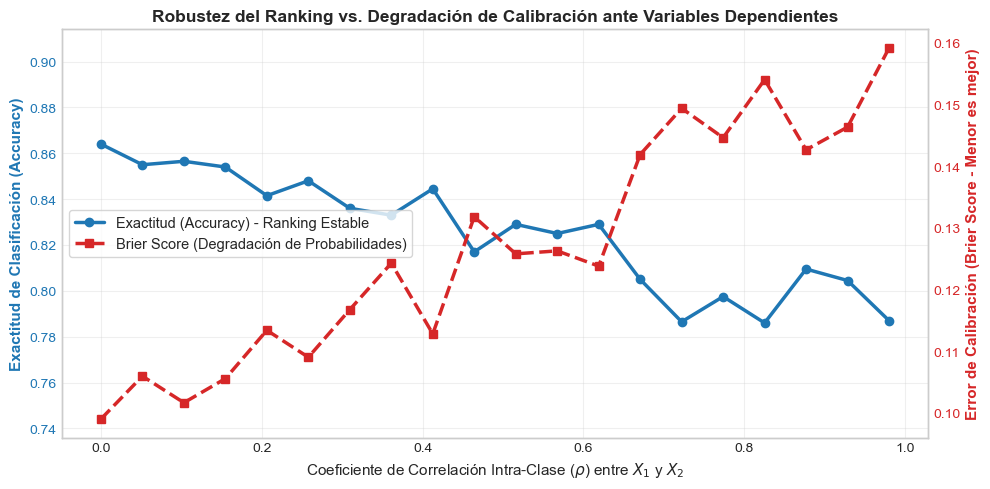

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, brier_score_loss

# 📊 Paso 4: Experimento de Simulación: Impacto de la Colinealidad en Exactitud vs Calibración
np.random.seed(42)
rhos = np.linspace(0.0, 0.98, 20)
acc_list, brier_list = [], []

for rho in rhos:
    # Matriz de covarianza con correlación intra-clase rho entre X1 y X2
    cov = np.array([[1.0, rho], [rho, 1.0]])
    X0 = np.random.multivariate_normal(mean=[-0.8, -0.8], cov=cov, size=1000)
    X1 = np.random.multivariate_normal(mean=[0.8, 0.8], cov=cov, size=1000)
    
    X_sim = np.vstack([X0, X1])
    y_sim = np.array([0] * 1000 + [1] * 1000)
    
    # Entrenamos GaussianNB (que ignora rho y asume matriz de covarianza diagonal)
    clf = GaussianNB().fit(X_sim, y_sim)
    y_pred = clf.predict(X_sim)
    y_prob = clf.predict_proba(X_sim)[:, 1]
    
    acc_list.append(accuracy_score(y_sim, y_pred))
    brier_list.append(brier_score_loss(y_sim, y_prob))

fig, ax1 = plt.subplots(figsize=(10, 5))

# Eje 1: Exactitud (Accuracy)
color_acc = '#1f77b4'
ax1.set_xlabel(r'Coeficiente de Correlación Intra-Clase ($\rho$) entre $X_1$ y $X_2$', fontsize=11)
ax1.set_ylabel('Exactitud de Clasificación (Accuracy)', color=color_acc, fontsize=11, fontweight='bold')
line1 = ax1.plot(rhos, acc_list, color=color_acc, lw=2.5, marker='o', label='Exactitud (Accuracy) - Ranking Estable')
ax1.tick_params(axis='y', labelcolor=color_acc)
ax1.set_ylim(min(acc_list) - 0.05, max(acc_list) + 0.05)
ax1.grid(alpha=0.3)

# Eje 2: Error de Calibración (Brier Score)
ax2 = ax1.twinx()
color_brier = '#d62728'
ax2.set_ylabel('Error de Calibración (Brier Score - Menor es mejor)', color=color_brier, fontsize=11, fontweight='bold')
line2 = ax2.plot(rhos, brier_list, color=color_brier, lw=2.5, marker='s', linestyle='--', label='Brier Score (Degradación de Probabilidades)')
ax2.tick_params(axis='y', labelcolor=color_brier)
ax2.grid(False)

# Leyenda unificada
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center left', frameon=True, facecolor='white', fontsize=10.5)

plt.title('Robustez del Ranking vs. Degradación de Calibración ante Variables Dependientes', fontsize=12.5, fontweight='bold')
plt.tight_layout()
plt.show()

Calibración (Brier Score): Mide si el valor numérico de la probabilidad refleja la frecuencia empírica real. Si un modelo le asigna $99\%$ de probabilidad de impago a 100 créditos, exactamente 99 deberían quebrar en la realidad. Si solo quiebran 80, el modelo está mal calibrado (sobreconfiado), aun cuando acierte todas las clasificaciones con un corte en $50\%$.

---

#### 1. Diferencia Conceptual Crítica: Exactitud vs. Calibración

Un clasificador probabilístico evaluado en producción debe responder a dos preguntas independientes:

1. **Capacidad Discriminativa (Exactitud / Ranking):** ¿Es capaz el modelo de separar a los clientes morosos de los no morosos?  
   * Solo evalúa si $P(Y = 1 \mid \mathbf{X}) > \text{Umbral}$ (usualmente 0.5).  
   * Si una muestra positiva recibe $0.51$ o $0.9999$, la exactitud es idéntica: cuenta como un acierto.
2. **Calibración Probabilística (Brier Score):** ¿La probabilidad que reporta el modelo refleja la realidad empírica?  
   * Se evalúa con el **Brier Score** (Error Cuadrático Medio de las probabilidades):
     $$BS = \frac{1}{N} \sum_{i=1}^N (p_i - y_i)^2$$
     *(Donde $p_i$ es la probabilidad predicha y $y_i \in \{0, 1\}$. Menor valor indica mejor calibración; $0$ es perfección).*

> ** Aclaración Clave:** Un modelo puede tener **excelente exactitud** y al mismo tiempo una **calibración pésima**. Por ejemplo, predecir probabilidades extremas ($0.9999$ o $0.0001$) mantiene las etiquetas intactas, pero infla enormemente el error cuadrático $BS$ cuando ocurren pequeñas fallas.

---

#### 2. Lectura Detallada de la Gráfica

* **Eje Horizontal ($\rho$ de 0.0 a 1.0):**  
  Representa el grado de colinealidad o redundancia entre $X_1$ y $X_2$ dentro de cada clase. A mayor $\rho$, más severa es la violación del supuesto de independencia condicional de Naive Bayes.
* **Línea Azul (Exactitud / Accuracy - Eje Izquierdo):**  
  * Con $\rho = 0.0$, el accuracy ronda el **$86\%$**.  
  * Con $\rho \to 1.0$, a pesar de que la correlación es casi perfecta, el accuracy apenas desciende al rango de **$78\% - 81\%$**.  
  * **Conclusión:** Naive Bayes es muy **robusto en ranking**. Aunque el supuesto teórico se viole violentamente, la frontera geométrica de decisión apenas cambia de orientación y sigue separando bien los grupos.
* **Línea Roja Punteada (Brier Score - Eje Derecho):**  
  * Con $\rho = 0.0$, el error es mínimo ($\approx 0.10$). Las probabilidades son representativas de la densidad real.  
  * Conforme $\rho$ aumenta, el error se dispara sostenidamente hasta casi **$0.16$**.  
  * **Conclusión:** Las probabilidades emitidas por el modelo pierden validez probabilística; están distorsionadas y artificialmente polarizadas.

---

#### 3. El Mecanismo Matemático: Doble Conteo de Evidencia

¿Por qué se degrada la calibración si las variables se correlacionan?

Naive Bayes descompone la verosimilitud asumiendo independencia:
$$P(X_1, X_2 \mid Y) = P(X_1 \mid Y) \cdot P(X_2 \mid Y)$$

Si $X_1$ y $X_2$ están fuertemente correlacionadas ($\rho \approx 1$), ambas variables aportan exactamente la misma información (son redundantes). Sin embargo, el algoritmo las multiplica como si fueran descubrimientos independientes:
$$P(X_1, X_2 \mid Y) \approx \big(P(X_1 \mid Y)\big)^2$$

* Si la evidencia favorece ligeramente a la Clase 1, elevarla al cuadrado la empuja artificialmente hacia **$0.999$**.
* Si favorece a la Clase 0, la empuja hacia **$0.001$**.
* **Efecto operativo:** El clasificador se vuelve **patológicamente sobreconfiado**.

---

#### 4. Implicaciones Prácticas de Negocio

| Escenario de Negocio | ¿Qué métrica manda? | ¿Es confiable Naive Bayes con variables correlacionadas? |
| :--- | :--- | :--- |
| **Filtro Anti-Spam / Motores de Búsqueda** | **Exactitud / AUC (Ranking)** | ✅ **Sí.** Solo nos interesa ordenar correos de más a menos sospechoso y cortar en el top. No importa si dice $99\%$ o $80\%$, con que quede arriba es suficiente. |
| **Aprobación de Créditos / Fijación de Primas de Seguro** | **Calibración (Brier Score)** | ❌ **No.** Si el modelo predice $95\%$ de probabilidad de pago para calcular la tasa de interés, pero la tasa real de pago en esa población es solo del $70\%$, la institución financiera sufrirá pérdidas masivas por subestimar el riesgo. |

> **🛠️ Solución en Producción:** Si el negocio requiere probabilidades fidedignas y se debe usar Naive Bayes sobre datos correlacionados, es mandatorio aplicar un paso posterior de calibración empírica como **Platt Scaling** (regresión logística unidimensional sobre los logits) o **Calibración Isotónica** (`sklearn.calibration.CalibratedClassifierCV`).


---

## 6. Laboratorio Práctico: Implementación Manual en Puro Python y NumPy

Para consolidar la mecánica matemática de los pasos anteriores, construiremos desde cero un clasificador **Naive Bayes Categórico** con suavizado de Laplace ($\alpha = 1.0$) en espacio logarítmico, aplicado a un comité de **Evaluación de Riesgo Crediticio**.

Posteriormente, auditaremos que nuestras tablas de probabilidad a priori, verosimilitudes logarítmicas y probabilidades posteriores coincidan con precisión de máquina ($\sim 10^{-16}$) frente a la implementación oficial `CategoricalNB` de Scikit-Learn.

In [21]:
# 1. Creación de Dataset Tabular Didáctico: Evaluación de Riesgo Crediticio
data_credito = [
    # [Historial_Pago, Nivel_Deuda, Garantia, Ingreso_Anual, Otorgar_Credito]
    ['Malo',         'Alta', 'Ninguna', 'Bajo',  'No'],
    ['Desconocido',  'Alta', 'Ninguna', 'Medio', 'No'],
    ['Desconocido',  'Baja', 'Ninguna', 'Medio', 'Si'],
    ['Desconocido',  'Baja', 'Ninguna', 'Alto',  'Si'],
    ['Desconocido',  'Baja', 'Aval',    'Alto',  'Si'],
    ['Buen_Pagador', 'Baja', 'Ninguna', 'Alto',  'Si'],
    ['Buen_Pagador', 'Baja', 'Aval',    'Alto',  'Si'],
    ['Buen_Pagador', 'Alta', 'Ninguna', 'Medio', 'Si'],
    ['Malo',         'Baja', 'Ninguna', 'Alto',  'No'],
    ['Buen_Pagador', 'Alta', 'Ninguna', 'Alto',  'Si'],
    ['Malo',         'Alta', 'Aval',    'Medio', 'No'],
    ['Desconocido',  'Alta', 'Ninguna', 'Alto',  'Si'],
    ['Buen_Pagador', 'Alta', 'Ninguna', 'Bajo',  'No'],
    ['Malo',         'Alta', 'Ninguna', 'Medio', 'No'],
    ['Malo',         'Baja', 'Aval',    'Medio', 'No'],
    ['Buen_Pagador', 'Baja', 'Ninguna', 'Medio', 'Si']
]

columnas = ['Historial_Pago', 'Nivel_Deuda', 'Garantia', 'Ingreso_Anual', 'Otorgar_Credito']
df_credito = pd.DataFrame(data_credito, columns=columnas)
print(f"Dimensiones del dataset: {df_credito.shape}")
df_credito.head(8)

Dimensiones del dataset: (16, 5)


,Historial_Pago,Nivel_Deuda,Garantia,Ingreso_Anual,Otorgar_Credito
0,Malo,Alta,Ninguna,Bajo,No
1,Desconocido,Alta,Ninguna,Medio,No
2,Desconocido,Baja,Ninguna,Medio,Si
3,Desconocido,Baja,Ninguna,Alto,Si
4,Desconocido,Baja,Aval,Alto,Si
5,Buen_Pagador,Baja,Ninguna,Alto,Si
6,Buen_Pagador,Baja,Aval,Alto,Si
7,Buen_Pagador,Alta,Ninguna,Medio,Si


In [22]:
# 2. Implementación desde Cero en NumPy (Espacio Logarítmico + Suavizado de Laplace + Log-Sum-Exp)
class ManualCategoricalNB:
    def __init__(self, alpha: float = 1.0):
        self.alpha = alpha
        self.classes_ = None
        self.class_log_prior_ = None
        self.feature_log_prob_ = []
        
    def fit(self, X: np.ndarray, y: np.ndarray):
        n_samples, n_features = X.shape
        self.classes_, class_counts = np.unique(y, return_counts=True)
        n_classes = len(self.classes_)
        
        # 1. Estado Previo (Priors en espacio logarítmico): ln P(Y = c_k)
        self.class_log_prior_ = np.log(class_counts / n_samples)
        
        # 2. El Generador de Datos (Tablas de log-verosimilitud por cada característica j)
        self.feature_log_prob_ = []
        for j in range(n_features):
            n_categories_j = int(np.max(X[:, j])) + 1
            log_prob_j = np.zeros((n_classes, n_categories_j))
            
            for idx_c, c in enumerate(self.classes_):
                X_c_j = X[y == c, j]
                # Conteo de frecuencias de cada categoría m dentro de la clase c
                counts_k = np.bincount(X_c_j.astype(int), minlength=n_categories_j)
                
                # Suavizado de Laplace / Lidstone:
                # P(x_j = m | Y = c) = (N_{c,j,m} + alpha) / (N_c + alpha * K_j)
                numerador = counts_k + self.alpha
                denominador = class_counts[idx_c] + self.alpha * n_categories_j
                log_prob_j[idx_c, :] = np.log(numerador / denominador)
                
            self.feature_log_prob_.append(log_prob_j)
        return self

    def _joint_log_likelihood(self, X: np.ndarray) -> np.ndarray:
        # Suma en espacio logarítmico: ln P(Y=c) + sum_j ln P(x_j | Y=c)
        jll = np.zeros((X.shape[0], len(self.classes_)))
        jll += self.class_log_prior_
        for j in range(X.shape[1]):
            categorias_observadas = X[:, j].astype(int)
            jll += self.feature_log_prob_[j][:, categorias_observadas].T
        return jll

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        jll = self._joint_log_likelihood(X)
        # 3 y 4. Normalización mediante el truco Log-Sum-Exp para obtener el Posterior exacto
        max_log = np.max(jll, axis=1, keepdims=True)
        exp_shifted = np.exp(jll - max_log)
        return exp_shifted / np.sum(exp_shifted, axis=1, keepdims=True)

    def predict(self, X: np.ndarray) -> np.ndarray:
        # Regla MAP: argmax_k ell_k(x) (sin necesidad de calcular el denominador)
        jll = self._joint_log_likelihood(X)
        return self.classes_[np.argmax(jll, axis=1)]

# Codificación ordinal de las variables
encoder = OrdinalEncoder()
X_encoded = encoder.fit_transform(df_credito.iloc[:, :-1])
y_encoded = (df_credito['Otorgar_Credito'] == 'Si').astype(int).values

# Entrenamiento de ambos modelos
modelo_manual = ManualCategoricalNB(alpha=1.0).fit(X_encoded, y_encoded)
modelo_sklearn = CategoricalNB(alpha=1.0).fit(X_encoded, y_encoded)

# Comparación rigurosa
proba_manual = modelo_manual.predict_proba(X_encoded)
proba_sklearn = modelo_sklearn.predict_proba(X_encoded)

diff_max = np.max(np.abs(proba_manual - proba_sklearn))
print(f"Diferencia máxima absoluta en probabilidades (Manual vs Scikit-Learn): {diff_max:.2e}")
assert np.allclose(proba_manual, proba_sklearn), "¡Alerta: Discrepancia detectada!"
print(" Validación exitosa: Nuestra implementación manual reproduce exactamente a Scikit-Learn.")

Diferencia máxima absoluta en probabilidades (Manual vs Scikit-Learn): 4.44e-16
✅ Validación exitosa: Nuestra implementación manual reproduce exactamente a Scikit-Learn.


In [23]:
# 3. Inferencia Explicable Paso a Paso para un Nuevo Solicitante de Crédito
nuevo_cliente_df = pd.DataFrame(
    [['Malo', 'Baja', 'Aval', 'Alto']],
    columns=['Historial_Pago', 'Nivel_Deuda', 'Garantia', 'Ingreso_Anual']
)
X_nuevo = encoder.transform(nuevo_cliente_df)

jll_nuevo = modelo_manual._joint_log_likelihood(X_nuevo)[0]
post_nuevo = modelo_manual.predict_proba(X_nuevo)[0]

print("=== AUDITORÍA BAYESIANA DEL NUEVO SOLICITANTE ===")
print(f"Perfil observado (x): {nuevo_cliente_df.iloc[0].to_dict()}\n")
print(f"1. Estado Previo (Priors): P(No) = {np.exp(modelo_manual.class_log_prior_[0]):.2%} | P(Si) = {np.exp(modelo_manual.class_log_prior_[1]):.2%}")
print(f"2. Log-Verosimilitud Conjunta Clase 'No' (0): {jll_nuevo[0]:.4f}  --> Posterior P(Y=No | X) = {post_nuevo[0]:.4%}")
print(f"3. Log-Verosimilitud Conjunta Clase 'Si' (1): {jll_nuevo[1]:.4f}  --> Posterior P(Y=Si | X) = {post_nuevo[1]:.4%}")
print(f"\nDecisión MAP Final: {'OTORGAR CRÉDITO (Sí)' if np.argmax(post_nuevo) == 1 else 'RECHAZAR CRÉDITO (No)'}")

=== AUDITORÍA BAYESIANA DEL NUEVO SOLICITANTE ===
Perfil observado (x): {'Historial_Pago': 'Malo', 'Nivel_Deuda': 'Baja', 'Garantia': 'Aval', 'Ingreso_Anual': 'Alto'}

1. Estado Previo (Priors): P(No) = 43.75% | P(Si) = 56.25%
2. Log-Verosimilitud Conjunta Clase 'No' (0): -5.1442  --> Posterior P(Y=No | X) = 55.1410%
3. Log-Verosimilitud Conjunta Clase 'Si' (1): -5.3505  --> Posterior P(Y=Si | X) = 44.8590%

Decisión MAP Final: RECHAZAR CRÉDITO (No)


---

## 7. Conclusiones y Errores Comunes en la Industria

1. **Confundir $P(\mathbf{x} \mid C_k)$ con $P(C_k \mid \mathbf{x})$ (Falacia de la Tasa Base):** Jamás despliegues un clasificador entrenado sobre un dataset balanceado artificialmente (50% fraude / 50% legítimo) sin sobrescribir el hiperparámetro `class_prior` con la verdadera prevalencia de producción (ej. `class_prior=[0.999, 0.001]`). Ignorar el *Prior* real inundará la operación con falsos positivos.
2. **Multiplicar probabilidades crudas fuera del espacio logarítmico:** Nunca implementes productoras directas de densidades o probabilidades en producción; a partir de unas pocas decenas de variables el *underflow* en `float64` destruirá las predicciones devolviendo `0.0` o `NaN`.
3. **Descartar Naive Bayes por correlaciones globales (`df.corr()`):** Que las características estén correlacionadas en la población general no viola el supuesto del modelo; Naive Bayes solo asume independencia *condicionada a la clase* ($X_i \perp\!\!\!\perp X_j \mid Y$), e incluso cuando existe colinealidad intra-clase, el ranking de clasificación MAP permanece notablemente robusto.
4. **Usar las probabilidades crudas de Naive Bayes para tomar decisiones financieras directas:** Si necesitas calcular el Valor Esperado de una pérdida ($\mathbb{E}[\text{Pérdida}] = P(\text{Default} \mid \mathbf{x}) \times \text{Monto}$), recuerda que la correlación entre variables empuja a Naive Bayes hacia `0` o `1`. En el **Notebook 04** aprenderemos a corregir esto mediante **Calibración Isotónica y de Platt**.

---
**Siguiente paso:** En el **Notebook 02 (`02_GaussianNB_Variables_Continuas_y_Fronteras.ipynb`)** extenderemos este marco hacia variables continuas mediante densidades normales, deduciendo analíticamente sus estimadores MLE, el rol geométrico de su matriz de covarianza diagonal y por qué sus fronteras de decisión en $\mathbb{R}^D$ son cuadráticas.